# HSF CMS Higgs-to-WW classification

**Om and Rishabh**

We compare kinematic features in four filename-labelled ROOT samples to see how well a classifier separates the Higgs-labelled file from DY, Top and WW. The four training files support development and validation; after fixing the model and threshold, we evaluate once on all four test files.

These are reduced files. Filenames do not verify CMS process identity, upstream selections or train/test independence. Results are exploratory and unweighted.

## Setup and experiment plan

Install the packages in requirements_hsf_ml.txt and place the eight ROOT files in new_datasets/. Test-event values are not read until after the freeze manifest is written.

We use one group-aware 75/25 split, compare a predeclared set of 12 configurations, fit at most nine feature sets, choose the threshold on validation data, then evaluate every test event.
CPU runs use up to four native threads for HistGradientBoosting and eight workers for Random Forest. Set `HSF_CPU_THREADS` to a positive integer to cap both when resources are constrained.


In [1]:
from __future__ import annotations

import hashlib
import json
import os
import pickle
import sys
import time
from itertools import combinations
from pathlib import Path

import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import scipy
from scipy.stats import ks_2samp
import sklearn
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    balanced_accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
    precision_recall_curve,
)
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from threadpoolctl import threadpool_limits
import uproot
from IPython.display import Image, Markdown, display

NOTEBOOK_STARTED = time.perf_counter()
CPU_AVAILABLE = (
    getattr(os, "process_cpu_count", lambda: None)()
    or os.cpu_count()
    or 1
)
CPU_OVERRIDE = os.environ.get("HSF_CPU_THREADS")
if CPU_OVERRIDE is None:
    HGB_THREADS = min(CPU_AVAILABLE, 4)
    RF_WORKERS = min(CPU_AVAILABLE, 8)
else:
    requested_threads = int(CPU_OVERRIDE)
    if requested_threads < 1:
        raise ValueError("HSF_CPU_THREADS must be a positive integer")
    HGB_THREADS = min(CPU_AVAILABLE, requested_threads)
    RF_WORKERS = min(CPU_AVAILABLE, requested_threads)

# Keep Joblib's worker count portable; avoid platform-specific physical-core probes.
os.environ["LOKY_MAX_CPU_COUNT"] = str(RF_WORKERS)


def estimator_thread_limit(cfg):
    """Bound native pools and avoid nesting them inside Random Forest workers."""
    return 1 if cfg["family"] == "random_forest" else HGB_THREADS


def score_group_ids(scores):
    """Encode exact score ties once for fast, exact bootstrap metrics."""
    _, group_ids = np.unique(scores, return_inverse=True)
    return group_ids.astype(np.int32, copy=False), int(group_ids.max()) + 1


def grouped_auc(pos_groups, neg_groups, group_count):
    """Compute ROC-AUC from exact score-tie counts."""
    pos_counts = np.bincount(pos_groups, minlength=group_count)
    neg_counts = np.bincount(neg_groups, minlength=group_count)
    n_pos = int(pos_counts.sum())
    n_neg = int(neg_counts.sum())
    neg_below = np.cumsum(neg_counts) - neg_counts
    return float(
        np.sum(pos_counts * (neg_below + 0.5 * neg_counts)) / (n_pos * n_neg)
    )


def grouped_auc_ap(pos_groups, neg_groups, group_count):
    """Compute ROC-AUC and average precision from exact score-tie counts."""
    pos_counts = np.bincount(pos_groups, minlength=group_count)
    neg_counts = np.bincount(neg_groups, minlength=group_count)
    n_pos = int(pos_counts.sum())
    n_neg = int(neg_counts.sum())
    neg_below = np.cumsum(neg_counts) - neg_counts
    auc = float(
        np.sum(pos_counts * (neg_below + 0.5 * neg_counts)) / (n_pos * n_neg)
    )

    descending_pos = pos_counts[::-1]
    descending_neg = neg_counts[::-1]
    occupied = (descending_pos + descending_neg) > 0
    true_positives = np.cumsum(descending_pos[occupied])
    false_positives = np.cumsum(descending_neg[occupied])
    ap = float(
        np.sum(
            (descending_pos[occupied] / n_pos)
            * (true_positives / (true_positives + false_positives))
        )
    )
    return auc, ap

SEED = 20261015
BOOTSTRAP_REPLICATES = 1000
BOOTSTRAP_SEED = SEED + 1
VALIDATION_FRACTION = 0.25
GROUP_SPLIT_FOLDS = 4
IMPORTANCE_REPEATS = 5
IMPORTANCE_ROW_CAP = 20000
MAX_FEATURE_SETS = 9
EPS_AUC = 0.005
EPS_AP = 0.01
THRESHOLD_RULE = "maximize validation balanced accuracy; ties use the highest threshold"
DEVELOPMENT_ROW_CAP = None
STEP_SIZE = "64 MB"
CLASSES = ["DY", "Higgs", "Top", "WW"]
POSITIVE_CLASS = "Higgs"
TRAIN_FILES = [f"{c}-train.root" for c in CLASSES]
TEST_FILES = [f"{c}-test.root" for c in CLASSES]
FEATURES = [
    "Jet1_eta",
    "Jet1_phi",
    "Jet1_pt",
    "Jet2_eta",
    "Jet2_phi",
    "Jet2_pt",
    "Lepton1_eta",
    "Lepton1_phi",
    "Lepton1_pt",
    "Lepton2_eta",
    "Lepton2_phi",
    "Lepton2_pt",
    "PuppiMET_phi",
    "PuppiMET_pt",
    "dphill",
    "jet_cat",
    "mjj",
    "mll",
    "mth",
    "mtw2",
    "njet",
    "ptll",
]
GROUPS = {
    "leptons": [
        "Lepton1_eta",
        "Lepton1_phi",
        "Lepton1_pt",
        "Lepton2_eta",
        "Lepton2_phi",
        "Lepton2_pt",
    ],
    "missing_momentum": ["PuppiMET_phi", "PuppiMET_pt"],
    "jets": [
        "Jet1_eta",
        "Jet1_phi",
        "Jet1_pt",
        "Jet2_eta",
        "Jet2_phi",
        "Jet2_pt",
        "mjj",
        "njet",
        "jet_cat",
    ],
    "dilepton_derived": ["dphill", "mll", "mth", "mtw2", "ptll"],
}
TOP_K = [5, 10, 15]
MODEL_CONFIGS = (
    [
        {
            "family": "logistic_regression",
            "id": f"logistic_C_{c:g}",
            "params": {"C": c, "max_iter": 2000},
        }
        for c in [0.1, 1.0, 10.0]
    ]
    + [
        {"family": "decision_tree", "id": f"decision_tree_{i + 1}", "params": p}
        for i, p in enumerate(
            [
                {"max_depth": 3, "min_samples_leaf": 20},
                {"max_depth": 8, "min_samples_leaf": 10},
                {"max_depth": None, "min_samples_leaf": 20},
            ]
        )
    ]
    + [
        {
            "family": "random_forest",
            "id": f"random_forest_{i + 1}",
            "params": {"n_estimators": 160, **p},
        }
        for i, p in enumerate(
            [
                {"max_depth": 8, "min_samples_leaf": 1},
                {"max_depth": 16, "min_samples_leaf": 5},
                {"max_depth": None, "min_samples_leaf": 10},
            ]
        )
    ]
    + [
        {
            "family": "hist_gradient_boosting",
            "id": f"hist_gradient_boosting_{i + 1}",
            "params": {
                **p,
                "max_iter": 100,
                "l2_regularization": 1.0,
                "early_stopping": False,
            },
        }
        for i, p in enumerate(
            [
                {"max_leaf_nodes": 7, "learning_rate": 0.05},
                {"max_leaf_nodes": 15, "learning_rate": 0.08},
                {"max_leaf_nodes": 31, "learning_rate": 0.1},
            ]
        )
    ]
)
assert len(MODEL_CONFIGS) == 12
assert all(
    sum(x["family"] == fam for x in MODEL_CONFIGS) == 3
    for fam in [
        "logistic_regression",
        "decision_tree",
        "random_forest",
        "hist_gradient_boosting",
    ]
)
REPO = Path.cwd().resolve()
DATA_DIR = REPO / "new_datasets"
OUT_BASE = REPO / "outputs" / "hsf_classification"
OUT_BASE.mkdir(parents=True, exist_ok=True)
version = 1
while (OUT_BASE / f"om_rishabh_hsf_classification_20261016_v{version}").exists():
    version += 1
OUT_DIR = OUT_BASE / f"om_rishabh_hsf_classification_20261016_v{version}"
OUT_DIR.mkdir(exist_ok=False)
# Test events stay gated until the model and freeze manifest are saved below.
FROZEN = False


def display_table(records, columns=None):
    """Render a compact Markdown table for notebook review."""
    records = list(records)
    if not records:
        display(Markdown("_No rows to display._"))
        return

    if columns is None:
        columns = list(dict.fromkeys(key for row in records for key in row))

    def format_value(value):
        if value is None:
            return "—"
        if isinstance(value, (float, np.floating)):
            return f"{value:.4g}"
        if isinstance(value, (dict, list, tuple)):
            return json.dumps(value, sort_keys=True, separators=(",", ":"))
        return str(value).replace("|", "\\|").replace("\n", " ")

    header = "| " + " | ".join(columns) + " |"
    separator = "| " + " | ".join("---" for _ in columns) + " |"
    body = [
        "| " + " | ".join(format_value(row.get(column)) for column in columns) + " |"
        for row in records
    ]
    display(Markdown("\n".join([header, separator, *body])))


def hash_file(path):
    h = hashlib.sha256()
    with Path(path).open("rb") as f:
        for b in iter(lambda: f.read(8 * 1024 * 1024), b""):
            h.update(b)
    return h.hexdigest()


def make_estimator(cfg):
    p = cfg["params"]
    steps = [("imputer", SimpleImputer(strategy="median"))]
    fam = cfg["family"]
    if fam == "logistic_regression":
        steps += [
            ("scaler", StandardScaler()),
            (
                "model",
                LogisticRegression(C=p["C"], max_iter=p["max_iter"], random_state=SEED),
            ),
        ]
    elif fam == "decision_tree":
        steps += [("model", DecisionTreeClassifier(**p, random_state=SEED))]
    elif fam == "random_forest":
        steps += [("model", RandomForestClassifier(**p, random_state=SEED, n_jobs=RF_WORKERS))]
    else:
        steps += [("model", HistGradientBoostingClassifier(**p, random_state=SEED))]
    return Pipeline(steps)


print(
    {
        "python": sys.version.split()[0],
        "numpy": np.__version__,
        "scipy": scipy.__version__,
        "scikit_learn": sklearn.__version__,
        "matplotlib": matplotlib.__version__,
        "uproot": uproot.__version__,
        "seed": SEED,
        "search_configurations": len(MODEL_CONFIGS),
        "bootstrap_replicates": BOOTSTRAP_REPLICATES,
        "available_cpus": CPU_AVAILABLE,
        "hist_gradient_boosting_threads": HGB_THREADS,
        "random_forest_workers": RF_WORKERS,
        "cpu_override": CPU_OVERRIDE,
        "output": str(OUT_DIR),
    }
)


{'python': '3.14.8', 'numpy': '2.5.4', 'scipy': '1.18.1', 'scikit_learn': '1.9.1', 'matplotlib': '3.11.2', 'uproot': '5.7.7', 'seed': 20261015, 'search_configurations': 12, 'bootstrap_replicates': 1000, 'available_cpus': 10, 'hist_gradient_boosting_threads': 4, 'random_forest_workers': 8, 'cpu_override': None, 'output': '/Users/falcon/Documents/docs/hsf-india-bvcoe-2026/outputs/hsf_classification/om_rishabh_hsf_classification_20261016_v6'}


## Input inventory

Hash all eight inputs and inspect ROOT objects, entry counts, branch names and types. Test files are metadata-only at this point.

In [2]:
FILES = TRAIN_FILES + TEST_FILES
missing = [f for f in FILES if not (DATA_DIR / f).is_file()]
if missing:
    raise FileNotFoundError(f"Missing inputs under {DATA_DIR}: {missing}")
inventory = []
for fn in FILES:
    p = DATA_DIR / fn
    row = {
        "filename": fn,
        "label": fn.split("-")[0],
        "split": fn.split("-")[1].split(".")[0],
        "bytes": p.stat().st_size,
        "sha256": hash_file(p),
    }
    with uproot.open(p) as rf:
        row["objects"] = [k.split(";")[0] for k in rf.keys()]
        if "Events" not in rf:
            raise KeyError(f"{fn} has no Events object")
        t = rf["Events"]
        row.update(
            entries=int(t.num_entries),
            object_class=t.classname,
            branches=list(t.keys()),
            types=t.typenames(),
        )
    inventory.append(row)
bad = []
for r in inventory:
    if set(r["branches"]) != set(FEATURES):
        bad.append((r["filename"], "branch list mismatch"))
    if r["types"] != inventory[0]["types"]:
        bad.append((r["filename"], "type schema mismatch"))
if bad:
    raise ValueError(bad)
display(
    Markdown(
        "|File|Label|Split|Entries|Size MB|SHA-256|\n|---|---|---|---:|---:|---|\n"
        + "\n".join(
            f"|{r['filename']}|{r['label']}|{r['split']}|{r['entries']:,}|{r['bytes'] / 1e6:.2f}|{r['sha256']}|"
            for r in inventory
        )
    )
)
print(
    {
        "ROOT_objects": inventory[0]["objects"],
        "object_class": inventory[0]["object_class"],
        "branch_types": inventory[0]["types"],
        "schemas_match": True,
        "test_values_read": False,
    }
)


|File|Label|Split|Entries|Size MB|SHA-256|
|---|---|---|---:|---:|---|
|DY-train.root|DY|train|39,103|2.03|65d8e6ef0da05be440e6d38288ef479a9dc9055b9340fabf679a7b54f5367948|
|Higgs-train.root|Higgs|train|21,584|5.58|efcda212fba7ce344787840f7282a0fb37495861bbc71f1c74ca219c78041195|
|Top-train.root|Top|train|20,453|1.35|30beb02050e2c007792bd7313e69fcaba42c564da08db6e3f8b06687f17f4841|
|WW-train.root|WW|train|112,816|5.66|3388cb9207ac8fdc3dd3a964522a8047f00b0e5ee58eedfa7c5560d184e494c4|
|DY-test.root|DY|test|29,979|1.55|6cc2ef3cf337e3d6a021b1026874b0d4baae1735ca8b8e46aa8866ced9366803|
|Higgs-test.root|Higgs|test|112,075|5.77|68f470682df3a15f59792d0a995ccfc3be34ebe9a5d2dfb6987f064252ca1c13|
|Top-test.root|Top|test|531,601|79.29|ac26218027a3190e8c785a3497f9f9cabe5ed4f2ab47ea20d5ea6769d9b1b3bd|
|WW-test.root|WW|test|185,741|9.29|d1c0a375017360823c756a5994dac2248e2c59ef8a41d150ad70ae959685efe0|

{'ROOT_objects': ['Events'], 'object_class': 'ROOT::RNTuple', 'branch_types': {'Jet1_eta': 'float', 'Jet1_phi': 'float', 'Jet1_pt': 'float', 'Jet2_eta': 'float', 'Jet2_phi': 'float', 'Jet2_pt': 'float', 'Lepton1_eta': 'float', 'Lepton1_phi': 'float', 'Lepton1_pt': 'float', 'Lepton2_eta': 'float', 'Lepton2_phi': 'float', 'Lepton2_pt': 'float', 'PuppiMET_phi': 'float', 'PuppiMET_pt': 'float', 'dphill': 'float', 'jet_cat': 'std::int32_t', 'mjj': 'float', 'mll': 'float', 'mth': 'float', 'mtw2': 'float', 'njet': 'std::int32_t', 'ptll': 'float'}, 'schemas_match': True, 'test_values_read': False}


## Training data, quality and feature checks

Filename labels are provisional: Higgs is positive; DY, Top and WW form the combined background. The whitelist contains the stored kinematic and derived columns. There are no separate event IDs or generator weights in this schema. We retain all rows and do not apply physics normalization.

In [3]:
def read_matrix(path):
    blocks = []
    with uproot.open(path) as rf:
        for chunk in rf["Events"].iterate(
            expressions=FEATURES, step_size=STEP_SIZE, library="np"
        ):
            blocks.append(np.column_stack([chunk[n] for n in FEATURES]))
    return (
        np.concatenate(blocks).astype(np.float32, copy=False)
        if blocks
        else np.empty((0, len(FEATURES)), np.float32)
    )


training_read_started = time.perf_counter()
train_by_class = {fn.split("-")[0]: read_matrix(DATA_DIR / fn) for fn in TRAIN_FILES}
training_read_seconds = time.perf_counter() - training_read_started
file_counts = {c: len(train_by_class[c]) for c in CLASSES}
X = np.concatenate([train_by_class[c] for c in CLASSES])
labels = np.concatenate([np.repeat(c, len(train_by_class[c])) for c in CLASSES])
y = (labels == POSITIVE_CLASS).astype(np.int8)
y_process = np.array([CLASSES.index(c) for c in labels], dtype=np.int8)
assert DEVELOPMENT_ROW_CAP is None or len(X) <= DEVELOPMENT_ROW_CAP
quality = []
for j, name in enumerate(FEATURES):
    a = X[:, j].astype(float)
    finite = np.isfinite(a)
    q = np.quantile(a[finite], [0, 0.01, 0.25, 0.5, 0.75, 0.99, 1])
    quality.append(
        {
            "feature": name,
            "dtype": str(X[:, j].dtype),
            "NaN": int(np.isnan(a).sum()),
            "infinite": int(np.isinf(a).sum()),
            "minus_999": int(np.sum(a == -999)),
            "min": q[0],
            "q01": q[1],
            "median": q[3],
            "q99": q[5],
            "max": q[6],
            "zero_fraction": float(np.mean(a == 0)),
        }
    )
display_table(quality)
print(
    {
        "training_counts": file_counts,
        "total_rows": len(X),
        "NaN_policy": "median imputation fitted on fitting rows",
        "infinity_policy": "invalid; report and exclude from inference",
        "sentinel_policy": "no automatic -999 mapping; inspect counts above",
    }
)


def wrap_phi(a):
    return (np.asarray(a, dtype=float) + np.pi) % (2 * np.pi) - np.pi


def massless_mll(a):
    return np.sqrt(
        np.maximum(
            2
            * a["Lepton1_pt"]
            * a["Lepton2_pt"]
            * (
                np.cosh(a["Lepton1_eta"] - a["Lepton2_eta"])
                - np.cos(wrap_phi(a["Lepton1_phi"] - a["Lepton2_phi"]))
            ),
            0,
        )
    )


checks = []
for c in CLASSES:
    a = {n: train_by_class[c][:, i].astype(float) for i, n in enumerate(FEATURES)}
    calc_ptll = np.hypot(
        a["Lepton1_pt"] * np.cos(a["Lepton1_phi"])
        + a["Lepton2_pt"] * np.cos(a["Lepton2_phi"]),
        a["Lepton1_pt"] * np.sin(a["Lepton1_phi"])
        + a["Lepton2_pt"] * np.sin(a["Lepton2_phi"]),
    )
    for name, calc, stored in [
        ("ptll", calc_ptll, a["ptll"]),
        ("dphill", wrap_phi(a["Lepton1_phi"] - a["Lepton2_phi"]), a["dphill"]),
        ("mll_massless", massless_mll(a), a["mll"]),
    ]:
        d = np.abs(calc - stored)
        checks.append(
            {
                "label": c,
                "calculation": name,
                "median_abs_difference": float(np.median(d)),
                "q95_abs_difference": float(np.quantile(d, 0.95)),
                "max_abs_difference": float(np.max(d)),
            }
        )
display_table(checks)
print(
    "Massless mll is a diagnostic only: lepton masses and flavor ordering are absent, so residuals do not establish an error."
)


| feature | dtype | NaN | infinite | minus_999 | min | q01 | median | q99 | max | zero_fraction |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| Jet1_eta | float32 | 0 | 0 | 0 | -4.681 | -3.285 | 0 | 3.283 | 4.683 | 0.6147 |
| Jet1_phi | float32 | 0 | 0 | 0 | -3.142 | -2.977 | 0 | 2.982 | 3.142 | 0.6147 |
| Jet1_pt | float32 | 0 | 0 | 0 | 0 | 0 | 0 | 283.2 | 2012 | 0.6147 |
| Jet2_eta | float32 | 0 | 0 | 0 | -4.696 | -2.714 | 0 | 2.728 | 4.692 | 0.8735 |
| Jet2_phi | float32 | 0 | 0 | 0 | -3.142 | -2.649 | 0 | 2.648 | 3.142 | 0.8735 |
| Jet2_pt | float32 | 0 | 0 | 0 | 0 | 0 | 0 | 110.6 | 871 | 0.8735 |
| Lepton1_eta | float32 | 0 | 0 | 0 | -2.5 | -2.34 | 0.001812 | 2.333 | 2.5 | 0 |
| Lepton1_phi | float32 | 0 | 0 | 0 | -3.142 | -3.077 | 0.003922 | 3.082 | 3.142 | 0 |
| Lepton1_pt | float32 | 0 | 0 | 0 | 25 | 25.39 | 45.27 | 214.5 | 941.8 | 0 |
| Lepton2_eta | float32 | 0 | 0 | 0 | -2.5 | -2.346 | -0.003062 | 2.339 | 2.5 | 0 |
| Lepton2_phi | float32 | 0 | 0 | 0 | -3.142 | -3.075 | -0.001355 | 3.08 | 3.142 | 0 |
| Lepton2_pt | float32 | 0 | 0 | 0 | 10 | 10.73 | 26.22 | 116.1 | 604.7 | 0 |
| PuppiMET_phi | float32 | 0 | 0 | 0 | -3.142 | -3.079 | 0.004033 | 3.083 | 3.142 | 0 |
| PuppiMET_pt | float32 | 0 | 0 | 0 | 0.03479 | 4.056 | 43.36 | 207.3 | 1203 | 0 |
| dphill | float32 | 0 | 0 | 0 | -3.142 | -3.126 | 0.007324 | 3.126 | 3.142 | 1.547e-05 |
| jet_cat | float32 | 0 | 0 | 0 | 0 | 0 | 0 | 2 | 2 | 0.6147 |
| mjj | float32 | 0 | 0 | 0 | 0 | 0 | 0 | 866.3 | 4777 | 0.6095 |
| mll | float32 | 0 | 0 | 0 | 0.125 | 9.387 | 65.55 | 366 | 1803 | 0 |
| mth | float32 | 0 | 0 | 0 | 0 | 1.508 | 65.8 | 240 | 1107 | 4.125e-05 |
| mtw2 | float32 | 0 | 0 | 0 | 0 | 0.7299 | 45.56 | 141.2 | 544 | 5.671e-05 |
| njet | float32 | 0 | 0 | 0 | 0 | 0 | 0 | 3 | 11 | 0.6147 |
| ptll | float32 | 0 | 0 | 0 | 0.06042 | 3.211 | 41.6 | 200.2 | 1141 | 0 |

{'training_counts': {'DY': 39103, 'Higgs': 21584, 'Top': 20453, 'WW': 112816}, 'total_rows': 193956, 'NaN_policy': 'median imputation fitted on fitting rows', 'infinity_policy': 'invalid; report and exclude from inference', 'sentinel_policy': 'no automatic -999 mapping; inspect counts above'}


| label | calculation | median_abs_difference | q95_abs_difference | max_abs_difference |
| --- | --- | --- | --- | --- |
| DY | ptll | 5.823e-07 | 2.199e-06 | 3.302e-05 |
| DY | dphill | 6.357e-08 | 2.384e-07 | 2.533e-07 |
| DY | mll_massless | 0.0002166 | 0.0006661 | 0.2576 |
| Higgs | ptll | 1.309e-06 | 5.052e-06 | 3.739e-05 |
| Higgs | dphill | 0 | 2.384e-07 | 2.384e-07 |
| Higgs | mll_massless | 0.0003486 | 0.001512 | 0.0348 |
| Top | ptll | 1.701e-06 | 7.055e-06 | 3.921e-05 |
| Top | dphill | 6.357e-08 | 2.384e-07 | 2.384e-07 |
| Top | mll_massless | 0.0001487 | 0.0008083 | 0.2027 |
| WW | ptll | 1.29e-06 | 5.558e-06 | 5.842e-05 |
| WW | dphill | 6.357e-08 | 2.384e-07 | 3.576e-07 |
| WW | mll_massless | 0.0001496 | 0.0007241 | 0.05975 |

Massless mll is a diagnostic only: lepton masses and flavor ordering are absent, so residuals do not establish an error.


## Duplicate policy and deterministic split

An exact duplicate full-feature vector is grouped by a stable hash of its canonical float32 bytes. Duplicate vectors are retained, and cross-label matches are reported separately. A four-fold StratifiedGroupKFold split is used; the fold closest to a 75/25 split and the full-sample class proportions becomes validation.

In [4]:
group_split_started = time.perf_counter()

# Group exact duplicate feature vectors so copies cannot leak across fitting and validation.
def row_key(row):
    v = np.asarray(row, dtype="<f4").copy()
    v[v == 0] = 0.0
    v[np.isnan(v)] = np.float32(np.nan)
    return hashlib.blake2b(v.tobytes(), digest_size=16).hexdigest()


groups = np.array([row_key(r) for r in X], dtype=object)
unique, inv, sizes = np.unique(groups, return_inverse=True, return_counts=True)
key_labels = {}
for k, l in zip(groups, labels):
    key_labels.setdefault(k, set()).add(l)
cross_keys = {k: v for k, v in key_labels.items() if len(v) > 1}
print(
    {
        "duplicate_groups": int(np.sum(sizes > 1)),
        "duplicate_rows_after_first": int(np.sum(sizes[sizes > 1] - 1)),
        "cross_label_feature_groups": len(cross_keys),
        "cross_label_rows": int(sum(np.sum(groups == k) for k in cross_keys)),
    }
)
counts = {c: int(np.sum(labels == c)) for c in CLASSES}
folds = list(
    StratifiedGroupKFold(
        n_splits=GROUP_SPLIT_FOLDS, shuffle=True, random_state=SEED
    ).split(X, y_process, groups)
)


def split_loss(pair):
    vi = pair[1]
    return abs(len(vi) / len(X) - VALIDATION_FRACTION) + sum(
        abs(np.mean(labels[vi] == c) - counts[c] / len(X)) for c in CLASSES
    )


# Choose the fold closest to the target size and class proportions; keep groups intact.
fit_i, val_i = min(folds, key=split_loss)
fit_i = np.asarray(fit_i)
val_i = np.asarray(val_i)
assert set(groups[fit_i]).isdisjoint(set(groups[val_i]))
X_fit, X_val = X[fit_i], X[val_i]
y_fit, y_val = y[fit_i], y[val_i]
lab_fit, lab_val = labels[fit_i], labels[val_i]
split_counts = {
    s: {c: int(np.sum(labs == c)) for c in CLASSES}
    for s, labs in [("fitting", lab_fit), ("validation", lab_val)]
}
print(
    {
        "method": "StratifiedGroupKFold(4), closest fold to 75/25 and class shares",
        "seed": SEED,
        "fit": len(fit_i),
        "validation": len(val_i),
        "class_counts": split_counts,
        "Higgs_prevalence_fit": float(y_fit.mean()),
        "Higgs_prevalence_validation": float(y_val.mean()),
        "group_overlap": False,
    }
)

group_split_seconds = time.perf_counter() - group_split_started


{'duplicate_groups': 0, 'duplicate_rows_after_first': 0, 'cross_label_feature_groups': 0, 'cross_label_rows': 0}


{'method': 'StratifiedGroupKFold(4), closest fold to 75/25 and class shares', 'seed': 20261015, 'fit': 145467, 'validation': 48489, 'class_counts': {'fitting': {'DY': 29327, 'Higgs': 16188, 'Top': 15340, 'WW': 84612}, 'validation': {'DY': 9776, 'Higgs': 5396, 'Top': 5113, 'WW': 28204}}, 'Higgs_prevalence_fit': 0.11128297139557425, 'Higgs_prevalence_validation': 0.11128297139557425, 'group_overlap': False}


## Fitting-partition exploration

The class-wise distributions and correlation matrix use fitting rows only. Correlation indicates linear association, not physical cause.

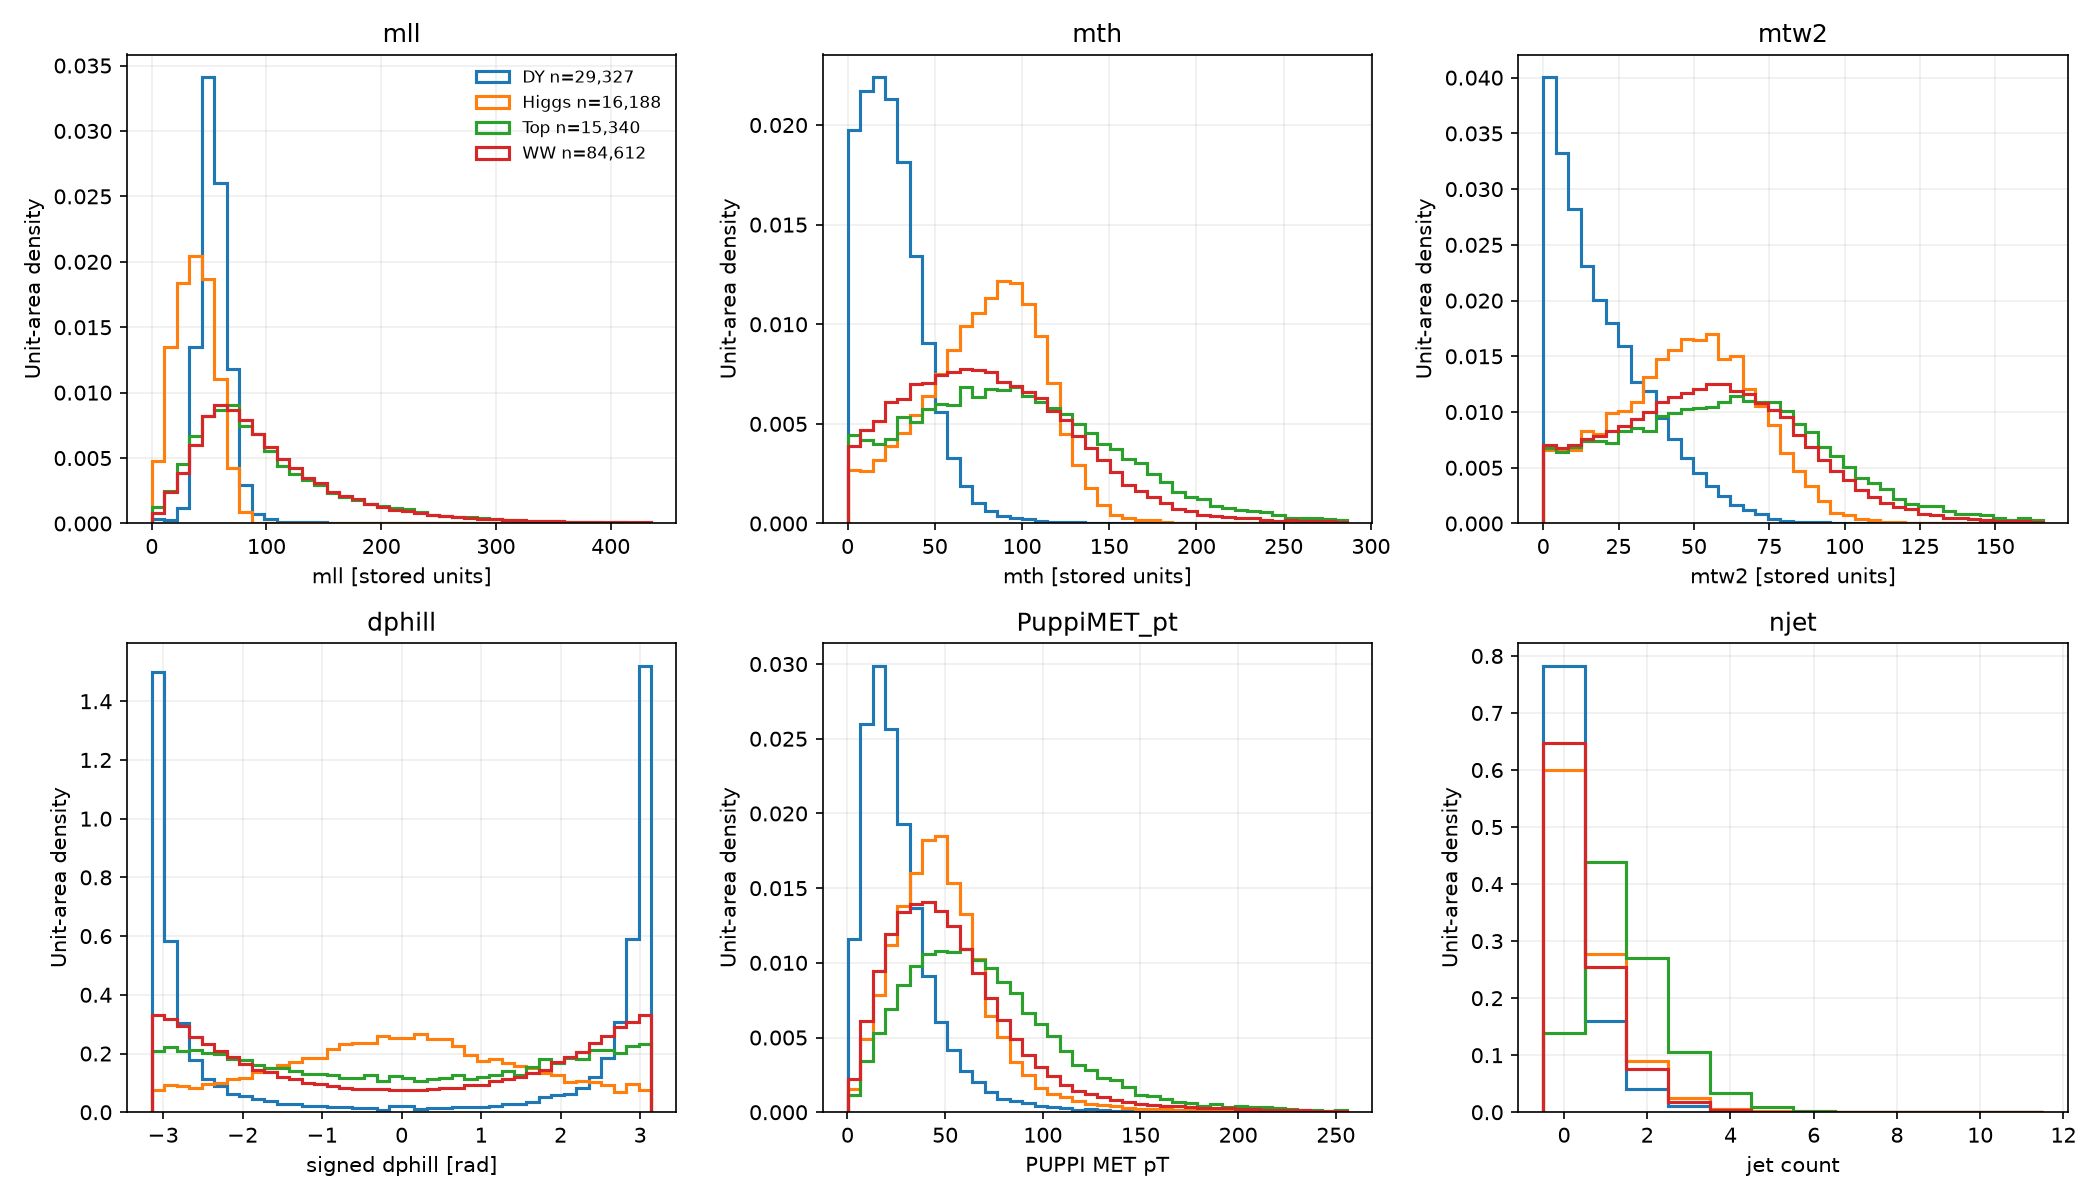

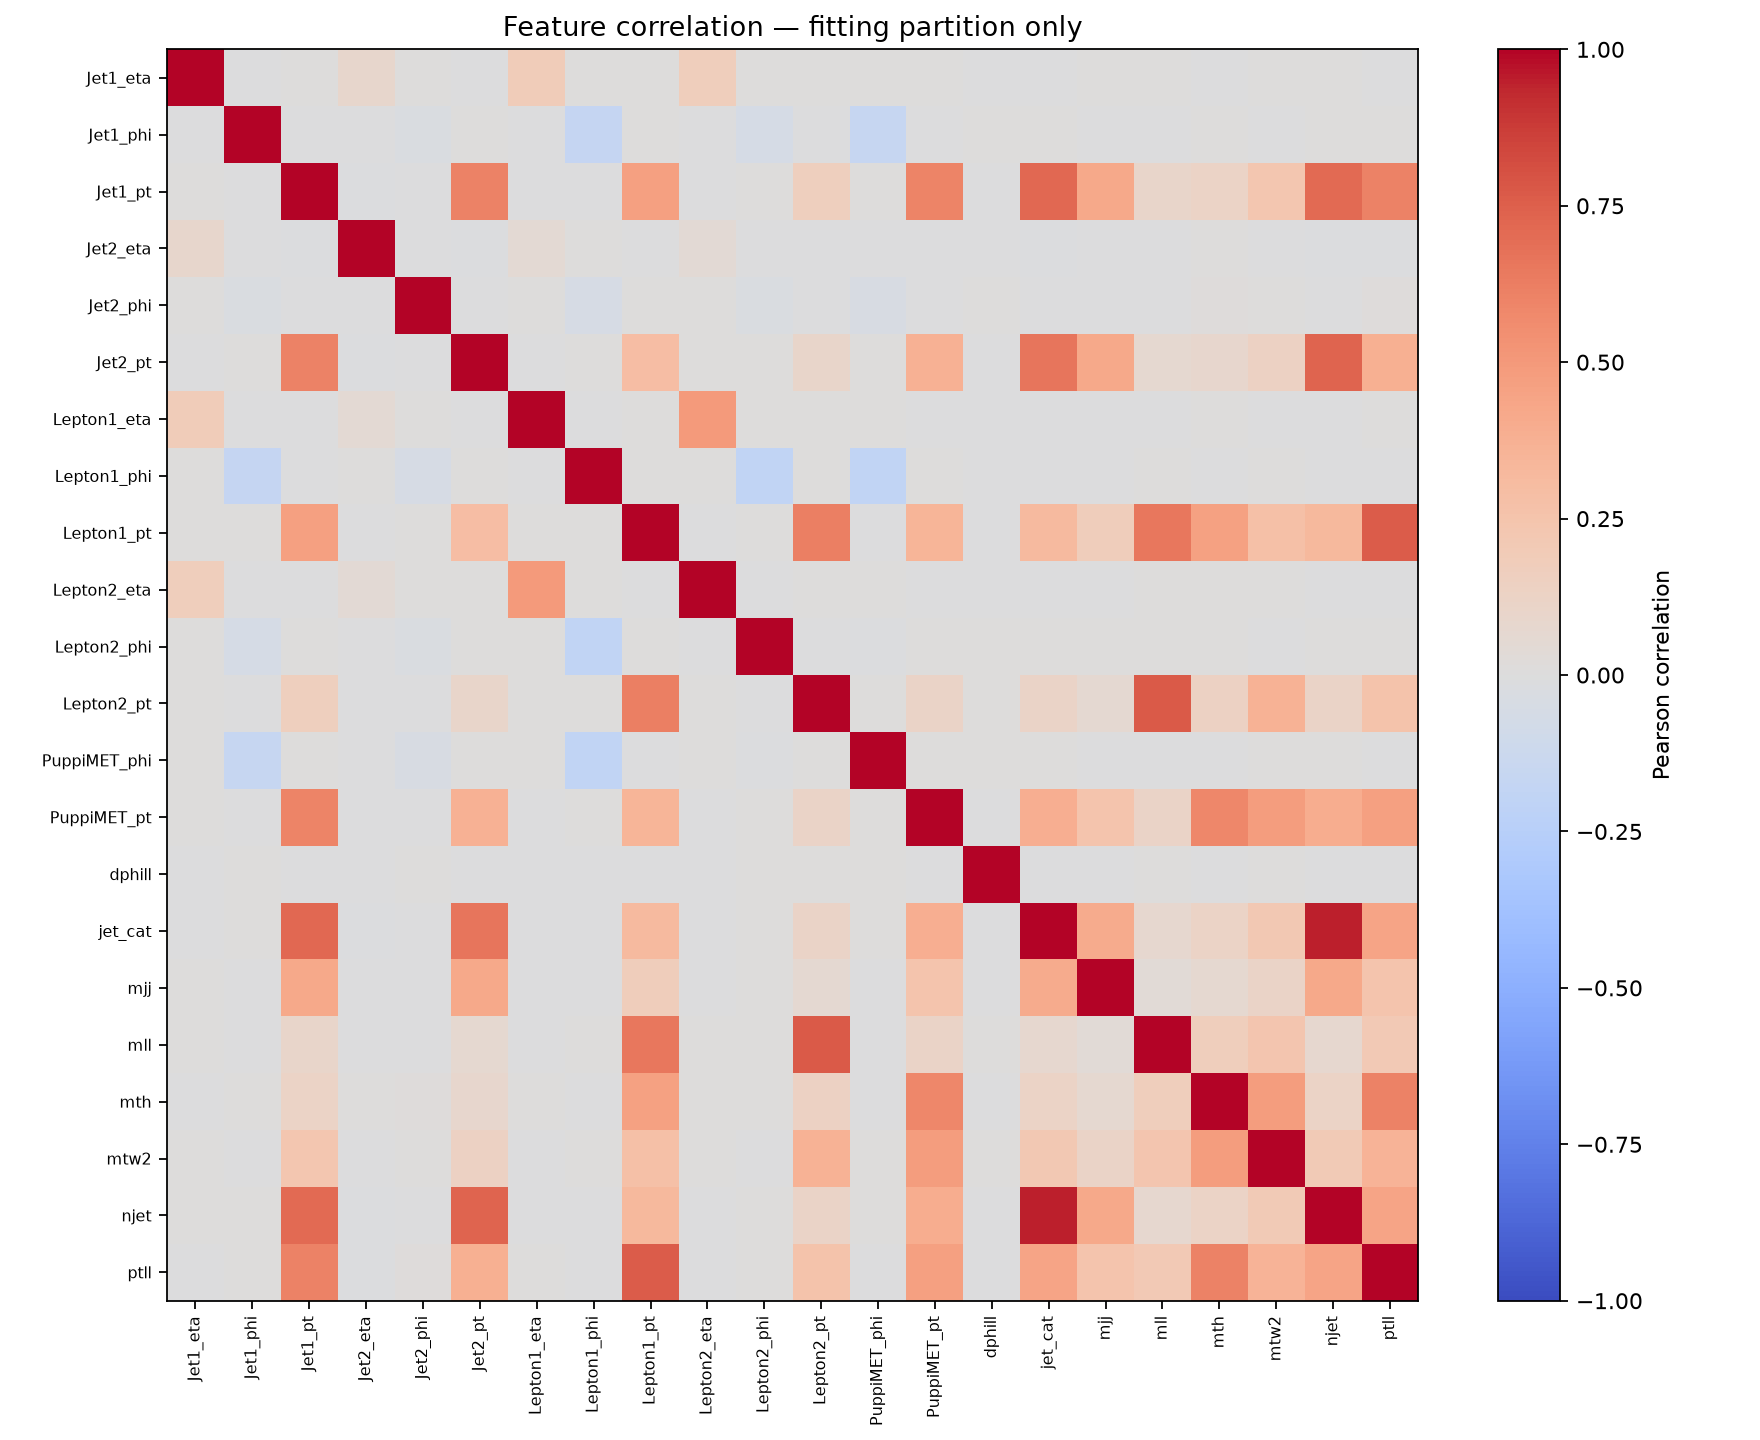

In [5]:
fig, axs = plt.subplots(2, 3, figsize=(14, 8))
for ax, (name, xlabel) in zip(
    axs.flat,
    [
        ("mll", "mll [stored units]"),
        ("mth", "mth [stored units]"),
        ("mtw2", "mtw2 [stored units]"),
        ("dphill", "signed dphill [rad]"),
        ("PuppiMET_pt", "PUPPI MET pT"),
        ("njet", "jet count"),
    ],
):
    j = FEATURES.index(name)
    hi = np.nanquantile(X_fit[:, j], 0.995)
    bins = (
        np.linspace(-np.pi, np.pi, 41)
        if name == "dphill"
        else (
            np.arange(
                int(np.nanmin(X_fit[:, j])) - 0.5, int(np.nanmax(X_fit[:, j])) + 1.5
            )
            if name == "njet"
            else np.linspace(np.nanmin(X_fit[:, j]), hi, 41)
        )
    )
    for c in CLASSES:
        vals = X_fit[lab_fit == c, j]
        ax.hist(
            vals,
            bins=bins,
            density=True,
            histtype="step",
            lw=1.5,
            label=f"{c} n={len(vals):,}",
        )
    ax.set(xlabel=xlabel, ylabel="Unit-area density", title=name)
    ax.grid(alpha=0.2)
axs[0, 0].legend(frameon=False, fontsize=8)
fig.tight_layout()
fig.savefig(OUT_DIR / "training_feature_distributions.png", dpi=150)
display(Image(filename=str(OUT_DIR / "training_feature_distributions.png")))
plt.close(fig)
corr = np.corrcoef(X_fit.astype(float), rowvar=False)
fig, ax = plt.subplots(figsize=(11, 9))
im = ax.imshow(corr, vmin=-1, vmax=1, cmap="coolwarm")
ax.set_xticks(range(len(FEATURES)), FEATURES, rotation=90, fontsize=7)
ax.set_yticks(range(len(FEATURES)), FEATURES, fontsize=7)
ax.set_title("Feature correlation — fitting partition only")
fig.colorbar(im, ax=ax, label="Pearson correlation")
fig.tight_layout()
fig.savefig(OUT_DIR / "training_feature_correlation.png", dpi=160)
display(Image(filename=str(OUT_DIR / "training_feature_correlation.png")))
plt.close(fig)


## Candidate Search

All 12 unweighted configurations use the same full feature set and fitting/validation rows. Imputation is inside each pipeline; logistic regression also scales its inputs. Candidate table threshold-based metrics use 0.5 for comparison only.

In [6]:
def metrics(yy, ss, threshold):
    pred = (ss >= threshold).astype(np.int8)
    return {
        "ROC-AUC": float(roc_auc_score(yy, ss)),
        "average_precision": float(average_precision_score(yy, ss)),
        "accuracy": float(accuracy_score(yy, pred)),
        "balanced_accuracy": float(balanced_accuracy_score(yy, pred)),
        "precision": float(precision_score(yy, pred, zero_division=0)),
        "recall": float(recall_score(yy, pred, zero_division=0)),
        "F1": float(f1_score(yy, pred, zero_division=0)),
    }


models = {}
scores = {}
rows = []
started = time.perf_counter()
for cfg in MODEL_CONFIGS:
    est = make_estimator(cfg)
    t = time.perf_counter()
    thread_limit = estimator_thread_limit(cfg)
    with threadpool_limits(limits=thread_limit):
        est.fit(X_fit, y_fit)
        tr = est.predict_proba(X_fit)[:, 1]
        va = est.predict_proba(X_val)[:, 1]
    fit_s = time.perf_counter() - t
    m = metrics(y_val, va, 0.5)
    models[cfg["id"]] = est
    scores[cfg["id"]] = {"fit": tr, "validation": va}
    rows.append(
        {
            "id": cfg["id"],
            "family": cfg["family"],
            "params": cfg["params"],
            "fit_s": fit_s,
            "train_auc": float(roc_auc_score(y_fit, tr)),
            "validation": m,
            "gap": float(roc_auc_score(y_fit, tr) - m["ROC-AUC"]),
        }
    )
search_seconds = time.perf_counter() - started
candidate_fit_seconds = float(sum(r["fit_s"] for r in rows))
best = max(rows, key=lambda r: r["validation"]["ROC-AUC"])

# Encode each candidate's exact tied scores once; bootstrap draws remain event-level.
candidate_score_groups = {
    r["id"]: score_group_ids(scores[r["id"]]["validation"])
    for r in rows
}
# Paired resampling uses identical validation rows for every candidate comparison.
rng = np.random.default_rng(BOOTSTRAP_SEED)
pos = np.flatnonzero(y_val == 1)
neg = np.flatnonzero(y_val == 0)
boot = {r["id"]: np.empty(BOOTSTRAP_REPLICATES) for r in rows}
candidate_bootstrap_started = time.perf_counter()
for b in range(BOOTSTRAP_REPLICATES):
    pos_draw = rng.choice(pos, len(pos), replace=True)
    neg_draw = rng.choice(neg, len(neg), replace=True)
    for r in rows:
        group_ids, group_count = candidate_score_groups[r["id"]]
        boot[r["id"]][b] = grouped_auc(
            group_ids[pos_draw], group_ids[neg_draw], group_count
        )
candidate_bootstrap_seconds = time.perf_counter() - candidate_bootstrap_started
paired = {}
for r in rows:
    d = boot[best["id"]] - boot[r["id"]]
    paired[r["id"]] = {
        "SE": float(np.std(d, ddof=1)),
        "CI95": [float(np.quantile(d, 0.025)), float(np.quantile(d, 0.975))],
    }
short = [
    r
    for r in rows
    if best["validation"]["ROC-AUC"] - r["validation"]["ROC-AUC"]
    <= paired[r["id"]]["SE"]
]
complexity = {
    "logistic_regression": 0,
    "decision_tree": 1,
    "random_forest": 2,
    "hist_gradient_boosting": 3,
}
winner = max(
    short,
    key=lambda r: (
        r["validation"]["average_precision"],
        -r["gap"],
        -complexity[r["family"]],
    ),
)
candidate_table = [
    {
        "id": r["id"],
        "family": r["family"],
        "params": r["params"],
        "train_AUC": r["train_auc"],
        "val_AUC": r["validation"]["ROC-AUC"],
        "val_AP": r["validation"]["average_precision"],
        **{
            k + "_at_0.5": v
            for k, v in r["validation"].items()
            if k not in ["ROC-AUC", "average_precision"]
        },
        "train_val_AUC_gap": r["gap"],
        "fit_s": r["fit_s"],
        "paired_SE_vs_best": paired[r["id"]]["SE"],
    }
    for r in rows
]
display_table(candidate_table)
print(
    {
        "configurations": len(rows),
        "search_seconds": search_seconds,
        "candidate_fit_seconds": candidate_fit_seconds,
        "candidate_bootstrap_seconds": candidate_bootstrap_seconds,
        "raw_best_auc": best["id"],
        "one_SE_shortlist": [r["id"] for r in short],
        "selected": winner["id"],
        "rule": "AUC within paired-bootstrap SE, then AP, lower AUC gap, lower within-family complexity",
    }
)


| id | family | params | train_AUC | val_AUC | val_AP | accuracy_at_0.5 | balanced_accuracy_at_0.5 | precision_at_0.5 | recall_at_0.5 | F1_at_0.5 | train_val_AUC_gap | fit_s | paired_SE_vs_best |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| logistic_C_0.1 | logistic_regression | {"C":0.1,"max_iter":2000} | 0.8612 | 0.8654 | 0.41 | 0.8894 | 0.5711 | 0.5093 | 0.1616 | 0.2454 | -0.004156 | 0.5792 | 0.001475 |
| logistic_C_1 | logistic_regression | {"C":1.0,"max_iter":2000} | 0.8612 | 0.8653 | 0.4102 | 0.8895 | 0.5728 | 0.5103 | 0.1655 | 0.2499 | -0.004141 | 0.6009 | 0.001477 |
| logistic_C_10 | logistic_regression | {"C":10.0,"max_iter":2000} | 0.8612 | 0.8653 | 0.4102 | 0.8894 | 0.5729 | 0.51 | 0.1657 | 0.2501 | -0.00414 | 0.5479 | 0.001477 |
| decision_tree_1 | decision_tree | {"max_depth":3,"min_samples_leaf":20} | 0.866 | 0.8679 | 0.373 | 0.8887 | 0.5 | 0 | 0 | 0 | -0.001876 | 1.293 | 0.001281 |
| decision_tree_2 | decision_tree | {"max_depth":8,"min_samples_leaf":10} | 0.9054 | 0.8953 | 0.456 | 0.8932 | 0.6167 | 0.5415 | 0.2611 | 0.3523 | 0.01004 | 2.559 | 0.0009829 |
| decision_tree_3 | decision_tree | {"max_depth":null,"min_samples_leaf":20} | 0.9504 | 0.8391 | 0.3932 | 0.8819 | 0.6547 | 0.4609 | 0.3625 | 0.4058 | 0.1113 | 3.611 | 0.002135 |
| random_forest_1 | random_forest | {"max_depth":8,"min_samples_leaf":1,"n_estimators":160} | 0.9077 | 0.8996 | 0.4844 | 0.8888 | 0.5003 | 1 | 0.000556 | 0.001111 | 0.008143 | 10.22 | 0.0007201 |
| random_forest_2 | random_forest | {"max_depth":16,"min_samples_leaf":5,"n_estimators":160} | 0.9647 | 0.9069 | 0.5105 | 0.8976 | 0.6129 | 0.5963 | 0.2467 | 0.349 | 0.05781 | 13.24 | 0.0005169 |
| random_forest_3 | random_forest | {"max_depth":null,"min_samples_leaf":10,"n_estimators":160} | 0.9715 | 0.9071 | 0.5056 | 0.8978 | 0.6172 | 0.5943 | 0.2563 | 0.3582 | 0.0644 | 13.26 | 0.000503 |
| hist_gradient_boosting_1 | hist_gradient_boosting | {"early_stopping":false,"l2_regularization":1.0,"learning_rate":0.05,"max_iter":100,"max_leaf_nodes":7} | 0.9039 | 0.9044 | 0.5015 | 0.8966 | 0.5902 | 0.6101 | 0.1961 | 0.2968 | -0.0004553 | 1.942 | 0.0005336 |
| hist_gradient_boosting_2 | hist_gradient_boosting | {"early_stopping":false,"l2_regularization":1.0,"learning_rate":0.08,"max_iter":100,"max_leaf_nodes":15} | 0.9135 | 0.9098 | 0.5211 | 0.8996 | 0.6353 | 0.5998 | 0.2952 | 0.3957 | 0.003726 | 2.824 | 0.0002568 |
| hist_gradient_boosting_3 | hist_gradient_boosting | {"early_stopping":false,"l2_regularization":1.0,"learning_rate":0.1,"max_iter":100,"max_leaf_nodes":31} | 0.9237 | 0.9102 | 0.5206 | 0.8995 | 0.645 | 0.5896 | 0.3176 | 0.4129 | 0.01343 | 2.542 | 0 |

{'configurations': 12, 'search_seconds': 54.29446258401731, 'candidate_fit_seconds': 53.215322206990095, 'candidate_bootstrap_seconds': 5.649319749994902, 'raw_best_auc': 'hist_gradient_boosting_3', 'one_SE_shortlist': ['hist_gradient_boosting_3'], 'selected': 'hist_gradient_boosting_3', 'rule': 'AUC within paired-bootstrap SE, then AP, lower AUC gap, lower within-family complexity'}


The winner is selected on one validation partition, so its validation performance can be optimistic. The paired bootstrap uses the same resampled events for each model.

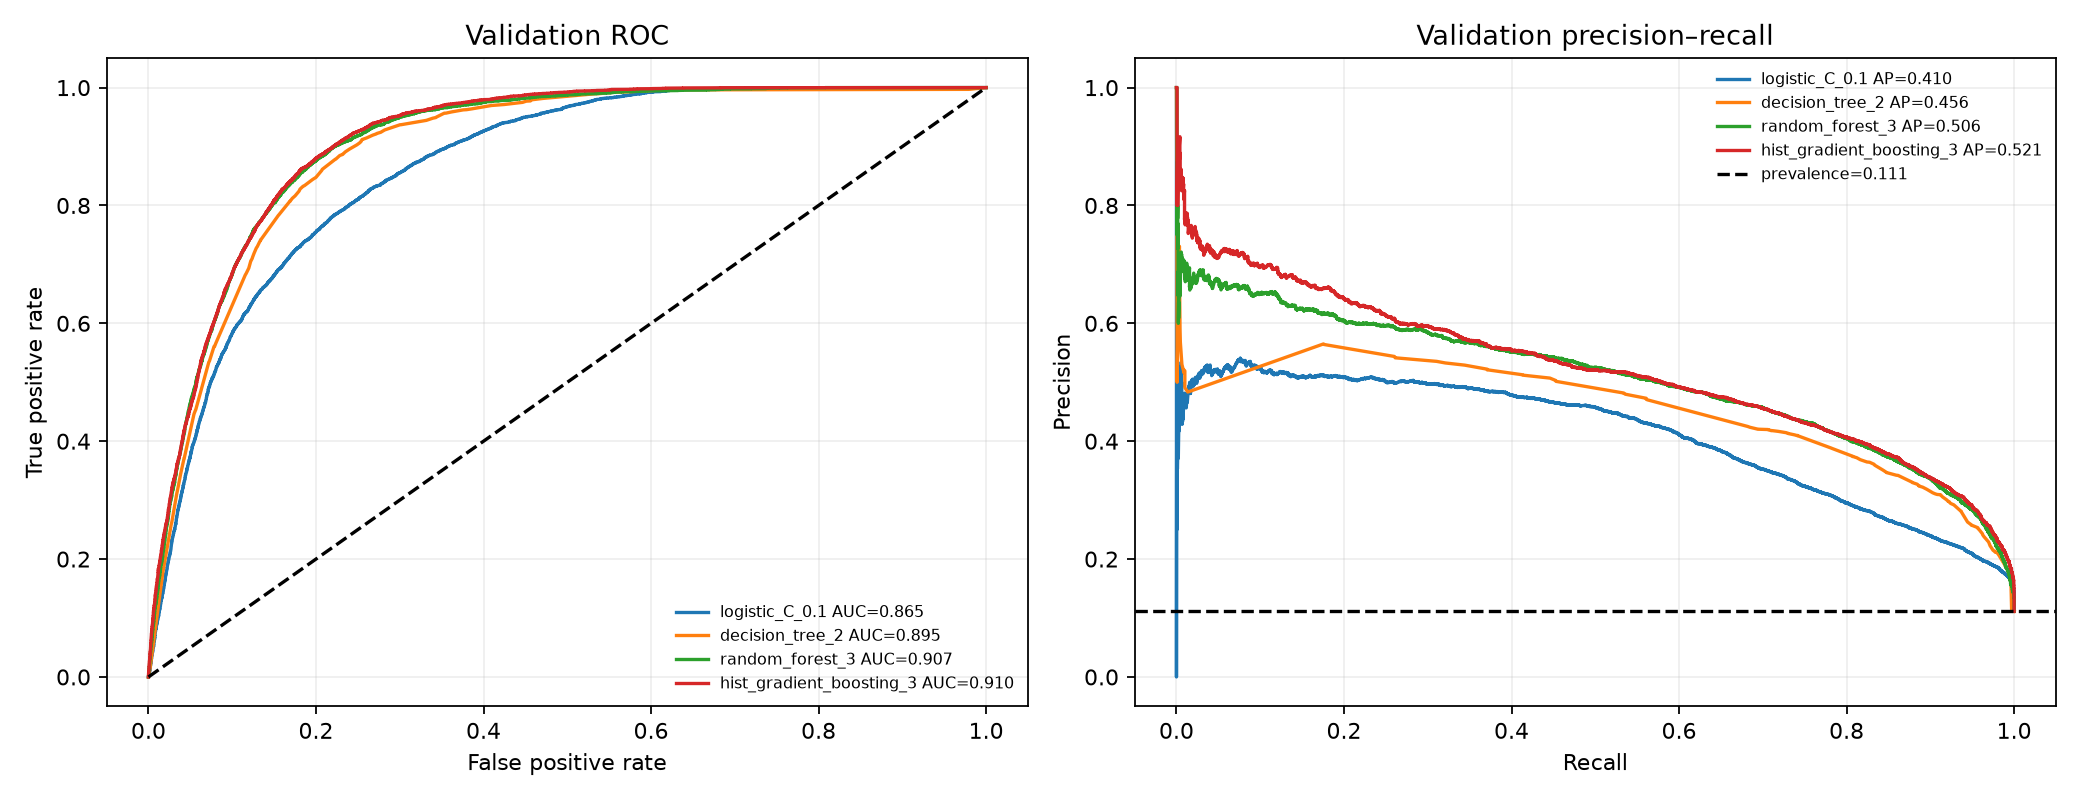

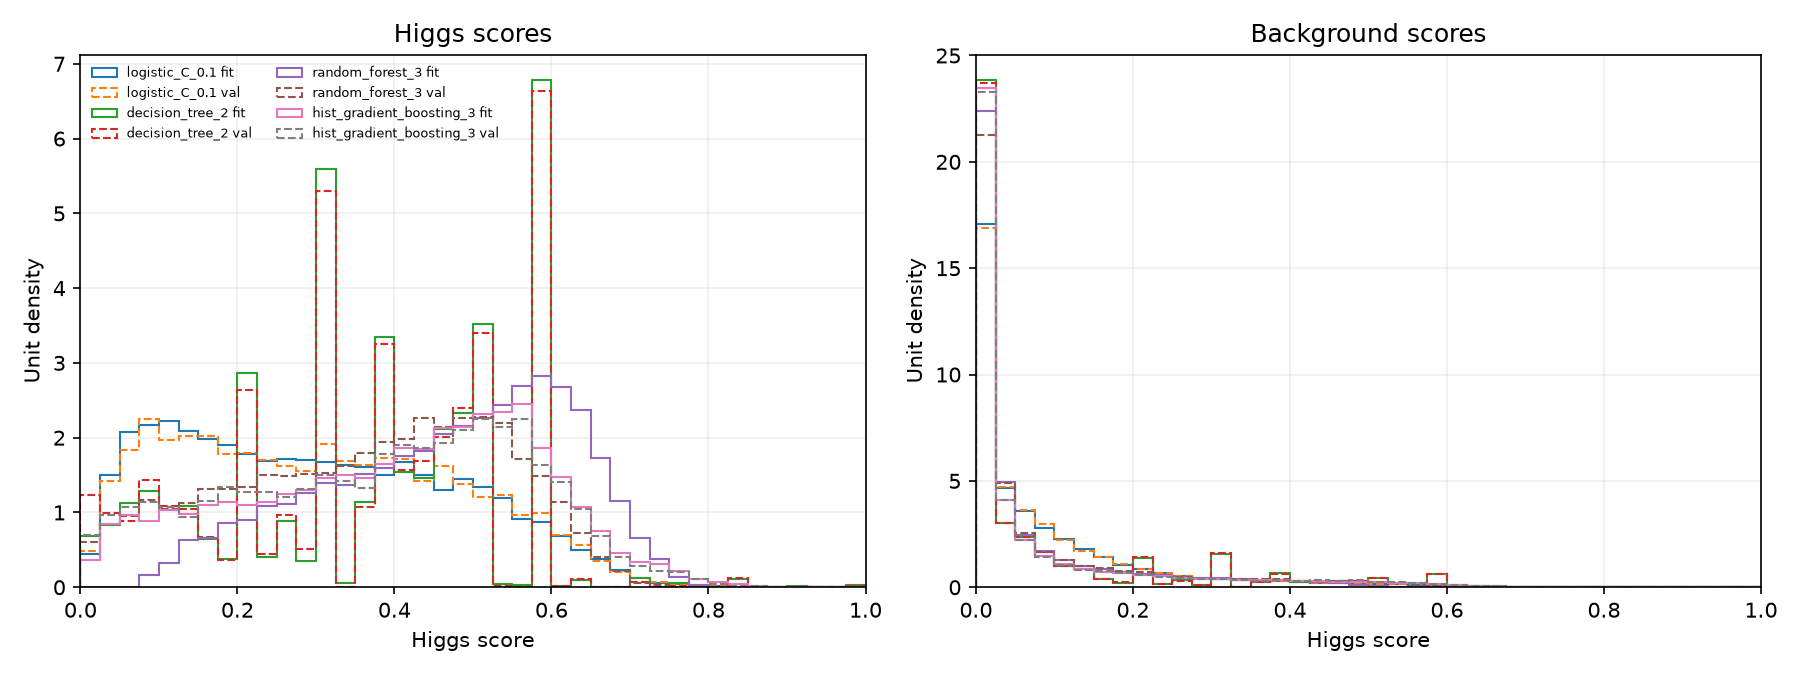

| configuration | class | n_fit | n_val | D | p |
| --- | --- | --- | --- | --- | --- |
| logistic_C_0.1 | Higgs | 16188 | 5396 | 0.02249 | 0.03289 |
| decision_tree_2 | Higgs | 16188 | 5396 | 0.02051 | 0.06553 |
| random_forest_3 | Higgs | 16188 | 5396 | 0.2313 | 8.123e-191 |
| hist_gradient_boosting_3 | Higgs | 16188 | 5396 | 0.03768 | 1.983e-05 |
| logistic_C_0.1 | Background | 129279 | 43093 | 0.004579 | 0.5054 |
| decision_tree_2 | Background | 129279 | 43093 | 0.005964 | 0.1997 |
| random_forest_3 | Background | 129279 | 43093 | 0.03072 | 6.309e-27 |
| hist_gradient_boosting_3 | Background | 129279 | 43093 | 0.007581 | 0.04849 |

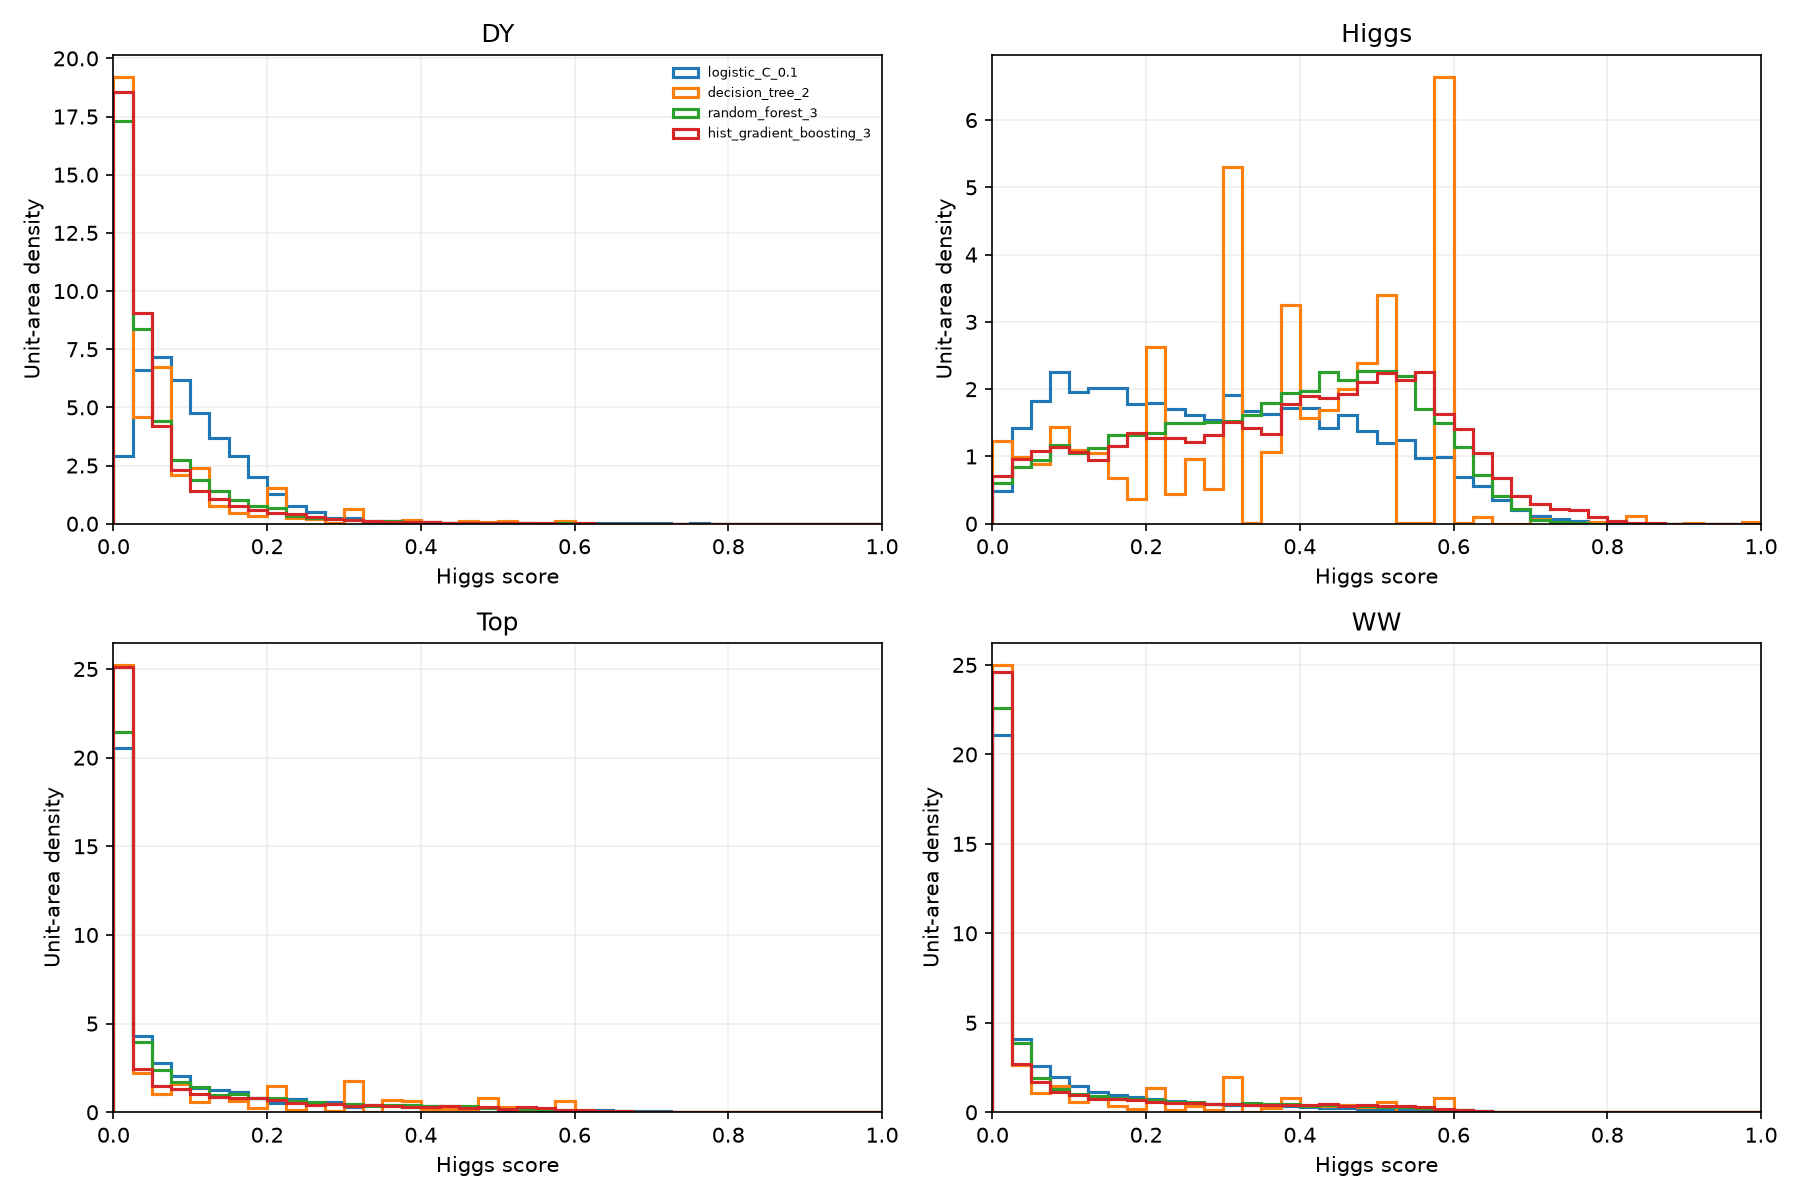

In [7]:
family_order = [
    "logistic_regression",
    "decision_tree",
    "random_forest",
    "hist_gradient_boosting",
]
family_best = [
    max([r for r in rows if r["family"] == f], key=lambda r: r["validation"]["ROC-AUC"])
    for f in family_order
]
short_ids = list(dict.fromkeys([r["id"] for r in family_best] + [winner["id"]]))
fig, axs = plt.subplots(1, 2, figsize=(13, 5))
for cid in short_ids:
    ss = scores[cid]["validation"]
    fpr, tpr, _ = roc_curve(y_val, ss)
    p, rec, _ = precision_recall_curve(y_val, ss)
    axs[0].plot(fpr, tpr, label=f"{cid} AUC={roc_auc_score(y_val, ss):.3f}")
    axs[1].plot(rec, p, label=f"{cid} AP={average_precision_score(y_val, ss):.3f}")
axs[0].plot([0, 1], [0, 1], "k--")
axs[0].set(
    xlabel="False positive rate", ylabel="True positive rate", title="Validation ROC"
)
axs[1].axhline(y_val.mean(), color="k", ls="--", label=f"prevalence={y_val.mean():.3f}")
axs[1].set(xlabel="Recall", ylabel="Precision", title="Validation precision–recall")
for ax in axs:
    ax.grid(alpha=0.2)
    ax.legend(frameon=False, fontsize=7)
fig.tight_layout()
fig.savefig(OUT_DIR / "candidate_roc_pr.png", dpi=160)
display(Image(filename=str(OUT_DIR / "candidate_roc_pr.png")))
plt.close(fig)
ks_rows = []
fig, axs = plt.subplots(1, 2, figsize=(12, 4.5))
bins = np.linspace(0, 1, 41)
for ax, truth, label in [(axs[0], 1, "Higgs"), (axs[1], 0, "Background")]:
    for cid in short_ids:
        a = scores[cid]["fit"][y_fit == truth]
        b = scores[cid]["validation"][y_val == truth]
        ax.hist(a, bins=bins, density=True, histtype="step", label=cid + " fit")
        ax.hist(
            b, bins=bins, density=True, histtype="step", ls="--", label=cid + " val"
        )
        k = ks_2samp(a, b, method="auto")
        ks_rows.append(
            {
                "configuration": cid,
                "class": label,
                "n_fit": len(a),
                "n_val": len(b),
                "D": float(k.statistic),
                "p": float(k.pvalue),
            }
        )
    ax.set(
        xlim=(0, 1),
        xlabel="Higgs score",
        ylabel="Unit density",
        title=label + " scores",
    )
    ax.grid(alpha=0.2)
axs[0].legend(frameon=False, fontsize=6, ncol=2)
fig.tight_layout()
fig.savefig(OUT_DIR / "candidate_train_val_scores.png", dpi=150)
display(Image(filename=str(OUT_DIR / "candidate_train_val_scores.png")))
plt.close(fig)
display_table(ks_rows)
# Validation score distributions by each filename-derived process for shortlisted models.
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, cls in zip(axes.flat, CLASSES):
    mask = lab_val == cls
    for cid in short_ids:
        ax.hist(
            scores[cid]["validation"][mask],
            bins=np.linspace(0, 1, 41),
            density=True,
            histtype="step",
            lw=1.5,
            label=cid,
        )
    ax.set(xlim=(0, 1), xlabel="Higgs score", ylabel="Unit-area density", title=cls)
    ax.grid(alpha=0.2)
axes[0, 0].legend(frameon=False, fontsize=6)
fig.tight_layout()
fig.savefig(OUT_DIR / "candidate_scores_by_process.png", dpi=150)
display(Image(filename=str(OUT_DIR / "candidate_scores_by_process.png")))
plt.close(fig)


## Feature importance and subsets

Permutation importance on validation rows proposes subsets; correlated inputs can share importance. We fit each subset from scratch. The candidate sets are the full list, four leave-group-out sets, top-5/10/15 ranked features, and all features except mll. At most nine unique sets are fitted.

| feature | mean_AUC_decrease | std |
| --- | --- | --- |
| mll | 0.3444 | 0.005462 |
| mth | 0.03824 | 0.0007726 |
| ptll | 0.03342 | 0.0004368 |
| Jet1_pt | 0.01005 | 0.0008931 |
| dphill | 0.00636 | 0.0006501 |
| PuppiMET_pt | 0.003987 | 0.0003148 |
| mtw2 | 0.003545 | 0.0005427 |
| Jet1_eta | 0.003157 | 0.0003643 |
| Lepton1_eta | 0.001746 | 0.000226 |
| Lepton1_pt | 0.001367 | 0.0001075 |
| Lepton2_pt | 0.001082 | 8.846e-05 |
| mjj | 0.001072 | 0.000144 |
| Lepton2_eta | 0.00103 | 0.0002087 |
| Jet2_pt | 0.0004442 | 0.0002181 |
| Jet2_eta | 3.969e-05 | 8.064e-05 |
| Jet2_phi | 3.143e-05 | 2.33e-05 |
| njet | 3.175e-06 | 1.204e-05 |
| jet_cat | 0 | 0 |
| Lepton2_phi | -5.228e-06 | 0.0001021 |
| PuppiMET_phi | -4.009e-05 | 0.0001136 |
| Jet1_phi | -7.198e-05 | 5.053e-05 |
| Lepton1_phi | -0.0001141 | 5.903e-05 |

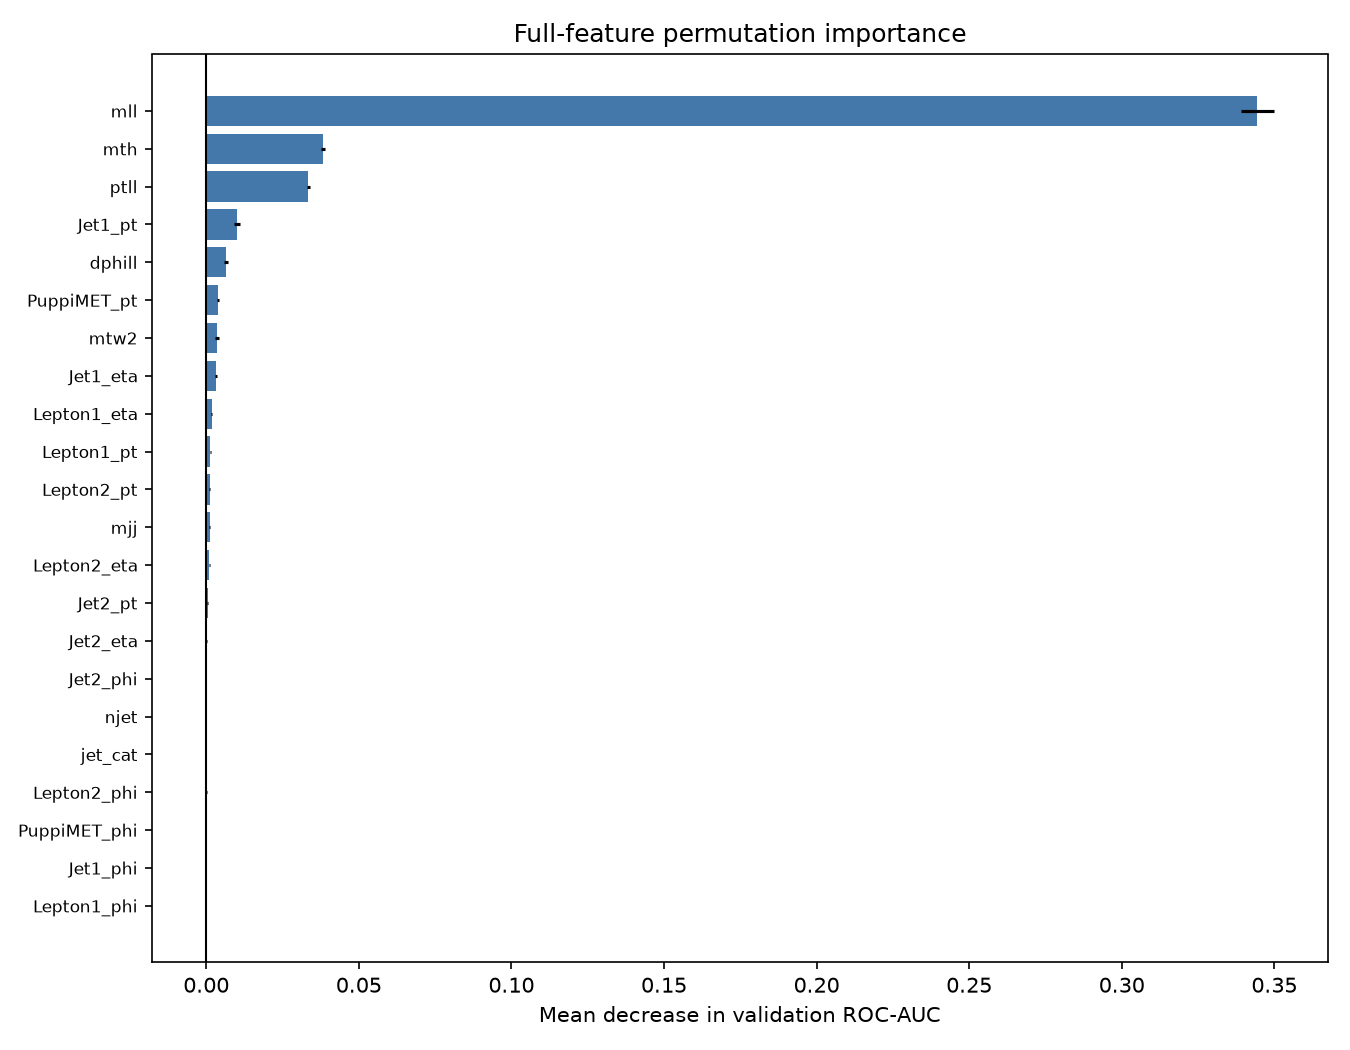

Feature sets before fitting: [('full', 22), ('without_leptons', 16), ('without_missing_momentum', 20), ('without_jets', 13), ('without_dilepton_derived', 17), ('top_5', 5), ('top_10', 10), ('top_15', 15), ('without_mll', 21)] count 9 importance_seconds 5.018773333984427 rows 20000


In [8]:
rng = np.random.default_rng(SEED)
imp_ix = rng.choice(len(X_val), min(IMPORTANCE_ROW_CAP, len(X_val)), replace=False)
t = time.perf_counter()
with threadpool_limits(limits=estimator_thread_limit(winner)):
    imp = permutation_importance(
        models[winner["id"]],
        X_val[imp_ix],
        y_val[imp_ix],
        scoring="roc_auc",
        n_repeats=IMPORTANCE_REPEATS,
        random_state=SEED,
        n_jobs=1,
    )
importance_seconds = time.perf_counter() - t
order = np.argsort(imp.importances_mean)[::-1]
ranked = [FEATURES[i] for i in order]
importance_table = [
    {
        "feature": FEATURES[i],
        "mean_AUC_decrease": float(imp.importances_mean[i]),
        "std": float(imp.importances_std[i]),
    }
    for i in order
]
display_table(importance_table)
fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(
    range(len(order)),
    imp.importances_mean[order],
    xerr=imp.importances_std[order],
    color="#4477aa",
)
ax.set_yticks(range(len(order)), [FEATURES[i] for i in order], fontsize=8)
ax.invert_yaxis()
ax.set(
    xlabel="Mean decrease in validation ROC-AUC",
    title="Full-feature permutation importance",
)
ax.axvline(0, color="k", lw=1)
fig.tight_layout()
fig.savefig(OUT_DIR / "importance_full.png", dpi=150)
display(Image(filename=str(OUT_DIR / "importance_full.png")))
plt.close(fig)
# Compare a small, predeclared set of domain groups and importance-ranked subsets.
sets = [("full", FEATURES.copy())]
for group, cols in GROUPS.items():
    sets.append(("without_" + group, [f for f in FEATURES if f not in cols]))
for k in TOP_K:
    sets.append((f"top_{k}", ranked[:k]))
sets.append(("without_mll", [f for f in FEATURES if f != "mll"]))
seen = set()
sets = [(n, fs) for n, fs in sets if not (tuple(fs) in seen or seen.add(tuple(fs)))]
assert len(sets) <= MAX_FEATURE_SETS
print(
    "Feature sets before fitting:",
    [(n, len(fs)) for n, fs in sets],
    "count",
    len(sets),
    "importance_seconds",
    importance_seconds,
    "rows",
    len(imp_ix),
)


In [9]:
subset_models = {}
subset_scores = {}
subset_rows = []
t = time.perf_counter()
for name, fs in sets:
    cols = [FEATURES.index(f) for f in fs]
    est = make_estimator(winner)
    with threadpool_limits(limits=estimator_thread_limit(winner)):
        est.fit(X_fit[:, cols], y_fit)
        ss = est.predict_proba(X_val[:, cols])[:, 1]
    m = metrics(y_val, ss, 0.5)
    subset_models[name] = est
    subset_scores[name] = ss
    subset_rows.append(
        {
            "name": name,
            "features": fs,
            "n": len(fs),
            "AUC": m["ROC-AUC"],
            "AP": m["average_precision"],
        }
    )
subset_fit_seconds = time.perf_counter() - t
subset_score_groups = {
    row["name"]: score_group_ids(subset_scores[row["name"]])
    for row in subset_rows
}
rng = np.random.default_rng(BOOTSTRAP_SEED + 10)
pos = np.flatnonzero(y_val == 1)
neg = np.flatnonzero(y_val == 0)
loss = {
    r["name"]: {
        "auc": np.empty(BOOTSTRAP_REPLICATES),
        "ap": np.empty(BOOTSTRAP_REPLICATES),
    }
    for r in subset_rows
}
# Paired bootstrap losses compare each reduced set with full on identical event draws.
subset_bootstrap_started = time.perf_counter()
for b in range(BOOTSTRAP_REPLICATES):
    pos_draw = rng.choice(pos, len(pos), replace=True)
    neg_draw = rng.choice(neg, len(neg), replace=True)
    full_groups, full_group_count = subset_score_groups["full"]
    full_auc, full_ap = grouped_auc_ap(
        full_groups[pos_draw], full_groups[neg_draw], full_group_count
    )
    for row in subset_rows:
        group_ids, group_count = subset_score_groups[row["name"]]
        auc, ap = grouped_auc_ap(
            group_ids[pos_draw], group_ids[neg_draw], group_count
        )
        loss[row["name"]]["auc"][b] = full_auc - auc
        loss[row["name"]]["ap"][b] = full_ap - ap
subset_bootstrap_seconds = time.perf_counter() - subset_bootstrap_started
comparison = []
for r in subset_rows:
    da = loss[r["name"]]["auc"]
    dp = loss[r["name"]]["ap"]
    comparison.append(
        {
            "feature_set": r["name"],
            "features": r["n"],
            "AUC": r["AUC"],
            "AP": r["AP"],
            "AUC_loss_full_minus_set": r["AUC"]
            - next(x["AUC"] for x in subset_rows if x["name"] == "full"),
            "AUC_loss_SE": float(np.std(da, ddof=1)),
            "AUC_loss_upper95": float(np.quantile(da, 0.95)),
            "AP_loss_full_minus_set": r["AP"]
            - next(x["AP"] for x in subset_rows if x["name"] == "full"),
            "AP_loss_SE": float(np.std(dp, ddof=1)),
            "AP_loss_upper95": float(np.quantile(dp, 0.95)),
            "noninferior": bool(
                np.quantile(da, 0.95) <= EPS_AUC and np.quantile(dp, 0.95) <= EPS_AP
            ),
        }
    )
display_table(comparison)
qual = [r for r in comparison if r["noninferior"] and r["feature_set"] != "full"]
selected_name = (
    min(qual, key=lambda r: (r["features"], -r["AUC"], -r["AP"]))["feature_set"]
    if qual
    else "full"
)
selected_features = next(fs for n, fs in sets if n == selected_name)
selected_estimator = subset_models[selected_name]
selected_val_score = subset_scores[selected_name]
print(
    {
        "feature_sets_fitted": len(sets),
        "subset_fit_seconds": subset_fit_seconds,
        "subset_bootstrap_seconds": subset_bootstrap_seconds,
        "EPS_AUC": EPS_AUC,
        "EPS_AP": EPS_AP,
        "selected_set": selected_name,
        "selected_features": selected_features,
        "rule": "reduced set only if upper one-sided 95% paired-bootstrap losses meet both tolerances; otherwise full",
    }
)


| feature_set | features | AUC | AP | AUC_loss_full_minus_set | AUC_loss_SE | AUC_loss_upper95 | AP_loss_full_minus_set | AP_loss_SE | AP_loss_upper95 | noninferior |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| full | 22 | 0.9102 | 0.5206 | 0 | 0 | 0 | 0 | 0 | 0 | True |
| without_leptons | 16 | 0.9082 | 0.5071 | -0.002029 | 0.0003711 | 0.00263 | -0.01346 | 0.003225 | 0.01889 | False |
| without_missing_momentum | 20 | 0.9099 | 0.5193 | -0.0003018 | 0.000259 | 0.0007209 | -0.00129 | 0.002021 | 0.004603 | True |
| without_jets | 13 | 0.9058 | 0.4949 | -0.004396 | 0.000461 | 0.005134 | -0.02571 | 0.004218 | 0.03263 | False |
| without_dilepton_derived | 17 | 0.8533 | 0.3935 | -0.05695 | 0.001896 | 0.06003 | -0.1271 | 0.006426 | 0.1374 | False |
| top_5 | 5 | 0.9053 | 0.4873 | -0.00497 | 0.0005089 | 0.005826 | -0.03325 | 0.004419 | 0.04031 | False |
| top_10 | 10 | 0.9096 | 0.5196 | -0.0005915 | 0.0003004 | 0.001081 | -0.001024 | 0.002608 | 0.005213 | True |
| top_15 | 15 | 0.9105 | 0.5233 | 0.0002898 | 0.00019 | -9.505e-06 | 0.002764 | 0.001558 | -0.0002389 | True |
| without_mll | 21 | 0.9002 | 0.5001 | -0.01 | 0.0006782 | 0.01113 | -0.02047 | 0.003409 | 0.02563 | False |

{'feature_sets_fitted': 9, 'subset_fit_seconds': 13.857993458019337, 'subset_bootstrap_seconds': 14.627428292005789, 'EPS_AUC': 0.005, 'EPS_AP': 0.01, 'selected_set': 'top_10', 'selected_features': ['mll', 'mth', 'ptll', 'Jet1_pt', 'dphill', 'PuppiMET_pt', 'mtw2', 'Jet1_eta', 'Lepton1_eta', 'Lepton1_pt'], 'rule': 'reduced set only if upper one-sided 95% paired-bootstrap losses meet both tolerances; otherwise full'}


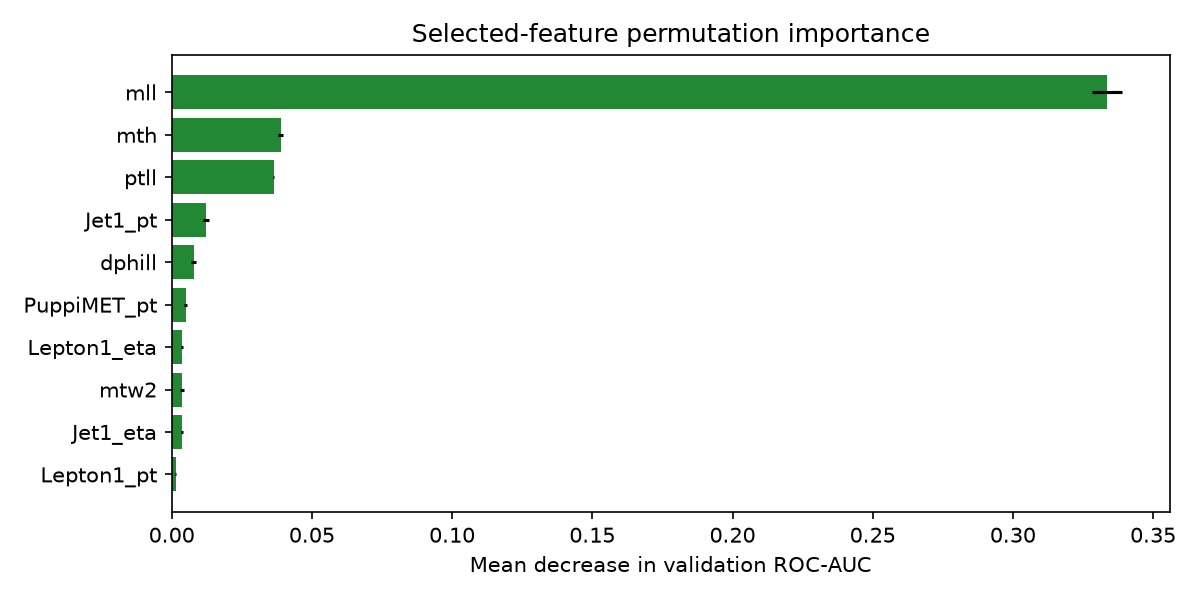

{'selected_validation_metrics': {'ROC-AUC': 0.9096383970145973, 'average_precision': 0.5195515817292351, 'accuracy': 0.8046773495019489, 'balanced_accuracy': 0.8411504781227465, 'precision': 0.3508309539497767, 'recall': 0.888065233506301, 'F1': 0.5029651010233535}, 'frozen_threshold': 0.11543311965789133, 'rule': 'maximize validation balanced accuracy; ties use the highest threshold'}


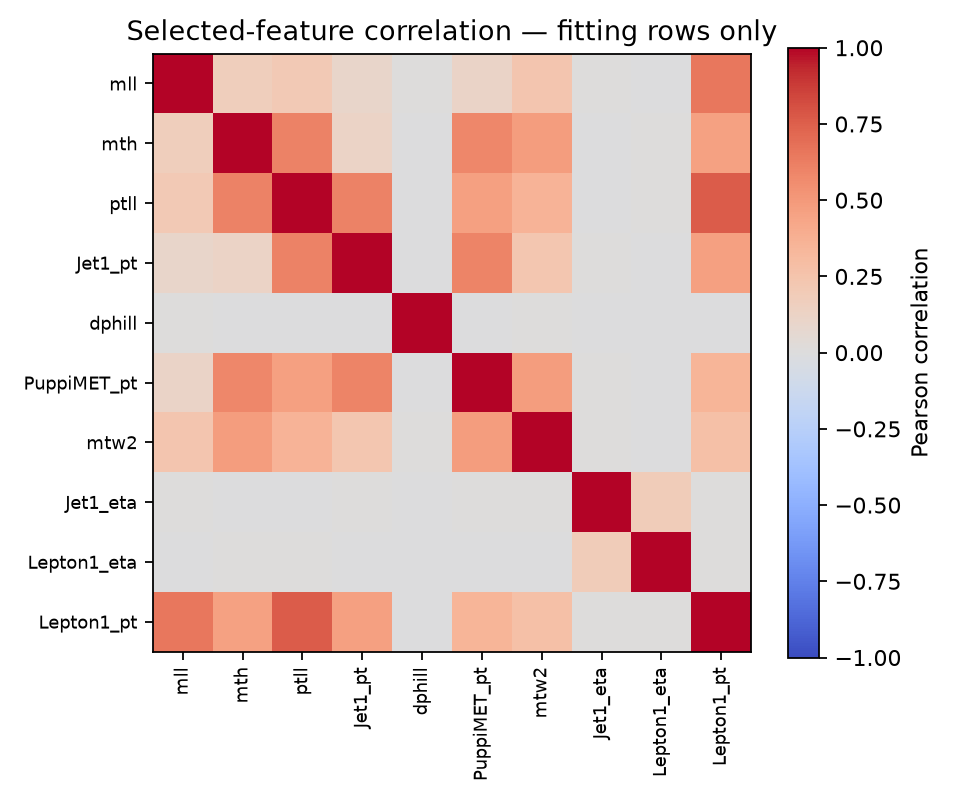

In [10]:
selected_cols = [FEATURES.index(f) for f in selected_features]
selected_importance_ref = "importance_full.png"
if selected_name != "full":
    with threadpool_limits(limits=estimator_thread_limit(winner)):
        selected_imp = permutation_importance(
            selected_estimator,
            X_val[imp_ix][:, selected_cols],
            y_val[imp_ix],
            scoring="roc_auc",
            n_repeats=IMPORTANCE_REPEATS,
            random_state=SEED,
            n_jobs=1,
        )
    fig, ax = plt.subplots(figsize=(8, max(4, 0.35 * len(selected_features))))
    oo = np.argsort(selected_imp.importances_mean)[::-1]
    ax.barh(
        range(len(oo)),
        selected_imp.importances_mean[oo],
        xerr=selected_imp.importances_std[oo],
        color="#228833",
    )
    ax.set_yticks(range(len(oo)), [selected_features[i] for i in oo])
    ax.invert_yaxis()
    ax.set(
        xlabel="Mean decrease in validation ROC-AUC",
        title="Selected-feature permutation importance",
    )
    fig.tight_layout()
    selected_importance_ref = "importance_selected.png"
    fig.savefig(OUT_DIR / selected_importance_ref, dpi=150)
    display(Image(filename=str(OUT_DIR / selected_importance_ref)))
    plt.close(fig)
else:
    print("Full-feature importance also applies to selected model.")

# Freeze the threshold from validation balanced accuracy; ties choose the highest threshold.
fpr, tpr, th = roc_curve(y_val, selected_val_score)
ba = (tpr + 1 - fpr) / 2
FROZEN_THRESHOLD = float(th[np.flatnonzero(ba == ba.max())[-1]])
val_metrics = metrics(y_val, selected_val_score, FROZEN_THRESHOLD)
fit_score = selected_estimator.predict_proba(X_fit[:, selected_cols])[:, 1]
fit_metrics = metrics(y_fit, fit_score, FROZEN_THRESHOLD)
print(
    {
        "selected_validation_metrics": val_metrics,
        "frozen_threshold": FROZEN_THRESHOLD,
        "rule": THRESHOLD_RULE,
    }
)
if selected_name != "full":
    selected_corr = np.corrcoef(X_fit[:, selected_cols].astype(float), rowvar=False)
    fig, ax = plt.subplots(
        figsize=(
            max(6, 0.45 * len(selected_features)),
            max(5, 0.45 * len(selected_features)),
        )
    )
    im = ax.imshow(selected_corr, vmin=-1, vmax=1, cmap="coolwarm")
    ax.set_xticks(
        range(len(selected_features)), selected_features, rotation=90, fontsize=8
    )
    ax.set_yticks(range(len(selected_features)), selected_features, fontsize=8)
    ax.set_title("Selected-feature correlation — fitting rows only")
    fig.colorbar(im, ax=ax, label="Pearson correlation")
    fig.tight_layout()
    fig.savefig(OUT_DIR / "selected_feature_correlation.png", dpi=160)
    display(Image(filename=str(OUT_DIR / "selected_feature_correlation.png")))
    plt.close(fig)


## Freeze manifest

This cell records all choices and validation results, saves the already-fitted fitting-partition estimator, and checks that reloading it preserves validation scores. It does not refit on validation.

In [11]:
cfg = next(c for c in MODEL_CONFIGS if c["id"] == winner["id"])
train_meta = [r for r in inventory if r["split"] == "train"]
test_meta = [r for r in inventory if r["split"] == "test"]
manifest = {
    "configuration": cfg,
    "selected_feature_set": selected_name,
    "features": selected_features,
    "preprocessing": "median imputer fitted on fitting rows; scaler only for logistic regression",
    "missing_policy": "NaNs median imputed from fitting rows; infinities invalid; no -999 replacement",
    "seed": SEED,
    "cpu_settings": {
        "available_cpus": CPU_AVAILABLE,
        "hist_gradient_boosting_threads": HGB_THREADS,
        "random_forest_workers": RF_WORKERS,
        "override": CPU_OVERRIDE,
    },
    "split": "StratifiedGroupKFold(4), closest fold to 75/25 and class proportions",
    "fit_rows": len(fit_i),
    "validation_rows": len(val_i),
    "split_counts": split_counts,
    "positive_label": "Higgs from filename",
    "background_labels": ["DY", "Top", "WW"],
    "training_files": [
        {"filename": r["filename"], "sha256": r["sha256"], "entries": r["entries"]}
        for r in train_meta
    ],
    "test_metadata_only": [
        {
            "filename": r["filename"],
            "sha256": r["sha256"],
            "entries": r["entries"],
            "objects": r["objects"],
            "branches": r["branches"],
            "types": r["types"],
        }
        for r in test_meta
    ],
    "threshold": FROZEN_THRESHOLD,
    "threshold_rule": THRESHOLD_RULE,
    "validation_metrics": val_metrics,
    "fitting_metrics": fit_metrics,
    "candidate_configurations": [
        {"id": r["id"], "family": r["family"], "params": r["params"]} for r in rows
    ],
    "candidate_count": len(rows),
    "feature_sets": [{"name": n, "features": fs} for n, fs in sets],
    "feature_set_count": len(sets),
    "bootstrap_replicates": BOOTSTRAP_REPLICATES,
    "importance": {
        "repeats": IMPORTANCE_REPEATS,
        "validation_row_cap": IMPORTANCE_ROW_CAP,
        "rows": len(imp_ix),
        "figure": selected_importance_ref,
    },
    "versions": {
        "python": sys.version.split()[0],
        "numpy": np.__version__,
        "scipy": scipy.__version__,
        "sklearn": sklearn.__version__,
        "uproot": uproot.__version__,
    },
    "labels_unverified_process_identity": True,
    "train_test_independence_verified": False,
    "unweighted": True,
}
model_path = OUT_DIR / "frozen_pipeline.pkl"
manifest_path = OUT_DIR / "freeze_manifest.json"
config_path = OUT_DIR / "frozen_config.json"
for p in [model_path, manifest_path, config_path]:
    if p.exists():
        raise FileExistsError(p)
with model_path.open("wb") as f:
    pickle.dump(
        {
            "estimator": selected_estimator,
            "features": selected_features,
            "threshold": FROZEN_THRESHOLD,
            "manifest": manifest,
        },
        f,
    )
manifest_path.write_text(json.dumps(manifest, indent=2))
config_path.write_text(
    json.dumps(
        {
            "configuration": cfg,
            "features": selected_features,
            "threshold": FROZEN_THRESHOLD,
            "seed": SEED,
        },
        indent=2,
    )
)
with model_path.open("rb") as f:
    reloaded = pickle.load(f)
roundtrip = reloaded["estimator"].predict_proba(X_val[:, selected_cols])[:, 1]
roundtrip_diff = float(np.max(np.abs(roundtrip - selected_val_score)))
assert np.allclose(roundtrip, selected_val_score, rtol=0, atol=1e-12)
# This guard is set only after model, configuration, manifest, and round-trip check succeed.
FROZEN = True
print(
    {
        "FROZEN": FROZEN,
        "manifest": str(manifest_path),
        "model": str(model_path),
        "model_bytes": model_path.stat().st_size,
        "config": str(config_path),
        "roundtrip_max_abs_error": roundtrip_diff,
        "model": cfg,
        "features": selected_features,
        "threshold": FROZEN_THRESHOLD,
        "configurations": len(rows),
        "feature_sets": len(sets),
    }
)


{'FROZEN': True, 'manifest': '/Users/falcon/Documents/docs/hsf-india-bvcoe-2026/outputs/hsf_classification/om_rishabh_hsf_classification_20261016_v6/freeze_manifest.json', 'model': {'family': 'hist_gradient_boosting', 'id': 'hist_gradient_boosting_3', 'params': {'max_leaf_nodes': 31, 'learning_rate': 0.1, 'max_iter': 100, 'l2_regularization': 1.0, 'early_stopping': False}}, 'model_bytes': 381097, 'config': '/Users/falcon/Documents/docs/hsf-india-bvcoe-2026/outputs/hsf_classification/om_rishabh_hsf_classification_20261016_v6/frozen_config.json', 'roundtrip_max_abs_error': 0.0, 'features': ['mll', 'mth', 'ptll', 'Jet1_pt', 'dphill', 'PuppiMET_pt', 'mtw2', 'Jet1_eta', 'Lepton1_eta', 'Lepton1_pt'], 'threshold': 0.11543311965789133, 'configurations': 12, 'feature_sets': 9}


## Frozen Model Diagnostics

The model and threshold are fixed. These cells now read all events from the four test files. They cannot run unless FROZEN was set by the manifest cell above.

In [12]:
# Test event values are read only after the freeze manifest has been written.
assert FROZEN, "Test event values require a recorded freeze manifest."
t = time.perf_counter()
test_by_class = {}
test_label_parts = []
for fn in TEST_FILES:
    assert FROZEN
    c = fn.split("-")[0]
    a = read_matrix(DATA_DIR / fn)
    test_by_class[c] = a
    test_label_parts.append(np.repeat(c, len(a)))
X_test = np.concatenate([test_by_class[c] for c in CLASSES])
lab_test = np.concatenate(test_label_parts)
y_test = (lab_test == POSITIVE_CLASS).astype(np.int8)
test_read_seconds = time.perf_counter() - t
assert len(X_test) == sum(r["entries"] for r in test_meta)
print(
    {
        "events_read": {c: len(test_by_class[c]) for c in CLASSES},
        "total": len(X_test),
        "read_seconds": test_read_seconds,
    }
)


{'events_read': {'DY': 29979, 'Higgs': 112075, 'Top': 531601, 'WW': 185741}, 'total': 859396, 'read_seconds': 0.7789610839972738}


### Data integrity and overlap

NaNs use the frozen imputer. Infinite rows are counted and excluded because they cannot be scored. All other rows remain. Exact feature matches to development and duplicates within test are descriptive; matching features do not establish event identity.

In [13]:
test_inf = np.isinf(X_test).any(axis=1)
test_nan = np.isnan(X_test).any(axis=1)
test_sentinel = (X_test == -999).any(axis=1)
valid = ~test_inf
test_keys = np.array([row_key(r) for r in X_test], dtype=object)
dev_keys = set(groups.tolist())
overlap = np.array([k in dev_keys for k in test_keys])
_, test_sizes = np.unique(test_keys, return_counts=True)
test_key_labels = {}
for key, cls in zip(test_keys, lab_test):
    test_key_labels.setdefault(key, set()).add(cls)
cross_label_test_keys = {k: v for k, v in test_key_labels.items() if len(v) > 1}
print(
    {
        "cross_label_test_feature_groups": len(cross_label_test_keys),
        "cross_label_test_rows": int(
            sum(np.sum(test_keys == k) for k in cross_label_test_keys)
        ),
        "rows": len(X_test),
        "infinite_rows_excluded": int(test_inf.sum()),
        "NaN_rows_median_imputed": int(test_nan.sum()),
        "minus_999_rows_retained": int(test_sentinel.sum()),
        "scored_rows": int(valid.sum()),
        "exact_test_development_matches": int(overlap.sum()),
        "test_duplicate_rows_after_first": int(np.sum(test_sizes[test_sizes > 1] - 1)),
    }
)


{'cross_label_test_feature_groups': 0, 'cross_label_test_rows': 0, 'rows': 859396, 'infinite_rows_excluded': 0, 'NaN_rows_median_imputed': 0, 'minus_999_rows_retained': 0, 'scored_rows': 859396, 'exact_test_development_matches': 0, 'test_duplicate_rows_after_first': 0}


### Test metrics and uncertainty

Metrics are unweighted; the frozen validation threshold is used for threshold-dependent metrics. The event bootstrap is stratified by binary class and assumes independent events.

In [14]:
cols = [FEATURES.index(f) for f in selected_features]
test_score = np.full(len(X_test), np.nan)
valid_test_rows = np.flatnonzero(valid)
test_inference_started = time.perf_counter()
with threadpool_limits(limits=HGB_THREADS):
    test_score[valid_test_rows] = selected_estimator.predict_proba(
        X_test[np.ix_(valid_test_rows, cols)]
    )[:, 1]
test_inference_seconds = time.perf_counter() - test_inference_started


def bootstrap_ci(yy, ss, B, seed):
    pos = np.flatnonzero(yy == 1)
    neg = np.flatnonzero(yy == 0)
    rng = np.random.default_rng(seed)
    aa = np.empty(B)
    pp = np.empty(B)
    # Map both classes through one shared score ordering for tie handling.
    all_groups, group_count = score_group_ids(ss)
    for b in range(B):
        pos_draw = rng.choice(pos, len(pos), replace=True)
        neg_draw = rng.choice(neg, len(neg), replace=True)
        aa[b], pp[b] = grouped_auc_ap(
            all_groups[pos_draw], all_groups[neg_draw], group_count
        )
    return {
        "ROC-AUC": [float(np.quantile(aa, 0.025)), float(np.quantile(aa, 0.975))],
        "average_precision": [
            float(np.quantile(pp, 0.025)),
            float(np.quantile(pp, 0.975)),
        ],
        "replicates": B,
        "seed": seed,
    }


splits = {
    "Fitting": (y_fit, fit_score),
    "Validation": (y_val, selected_val_score),
    "Test": (y_test[valid], test_score[valid]),
}
frozen_metrics = {}
bootstrap_seconds = {}
for i, (name, (yy, ss)) in enumerate(splits.items()):
    frozen_metrics[name] = metrics(yy, ss, FROZEN_THRESHOLD)
    if name in ["Validation", "Test"]:
        bootstrap_started = time.perf_counter()
        frozen_metrics[name]["95pct_CI"] = bootstrap_ci(
            yy, ss, BOOTSTRAP_REPLICATES, BOOTSTRAP_SEED + 20 + i
        )
        bootstrap_seconds[name.lower()] = time.perf_counter() - bootstrap_started
metric_rows = []
for split_name, values in frozen_metrics.items():
    row = {key: value for key, value in values.items() if key != "95pct_CI"}
    row["split"] = split_name
    confidence_intervals = values.get("95pct_CI", {})
    for metric, column in [
        ("ROC-AUC", "AUC 95% CI"),
        ("average_precision", "AP 95% CI"),
    ]:
        interval = confidence_intervals.get(metric)
        row[column] = f"[{interval[0]:.4f}, {interval[1]:.4f}]" if interval else "—"
    metric_rows.append(row)
display_table(metric_rows)
print(
    "Binary test classification includes all four test files; no physics-normalized yields are calculated."
)


| ROC-AUC | average_precision | accuracy | balanced_accuracy | precision | recall | F1 | split | AUC 95% CI | AP 95% CI |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 0.9215 | 0.5658 | 0.8105 | 0.8521 | 0.3602 | 0.9056 | 0.5154 | Fitting | — | — |
| 0.9096 | 0.5196 | 0.8047 | 0.8412 | 0.3508 | 0.8881 | 0.503 | Validation | [0.9065, 0.9127] | [0.5074, 0.5324] |
| 0.9187 | 0.5693 | 0.817 | 0.8448 | 0.407 | 0.8825 | 0.557 | Test | [0.9181, 0.9193] | [0.5666, 0.5722] |

Binary test classification includes all four test files; no physics-normalized yields are calculated.


### Frozen-model plots

ROC, precision–recall, confusion matrix and score plots use the same frozen estimator. AP baselines show each split's filename-derived Higgs prevalence.

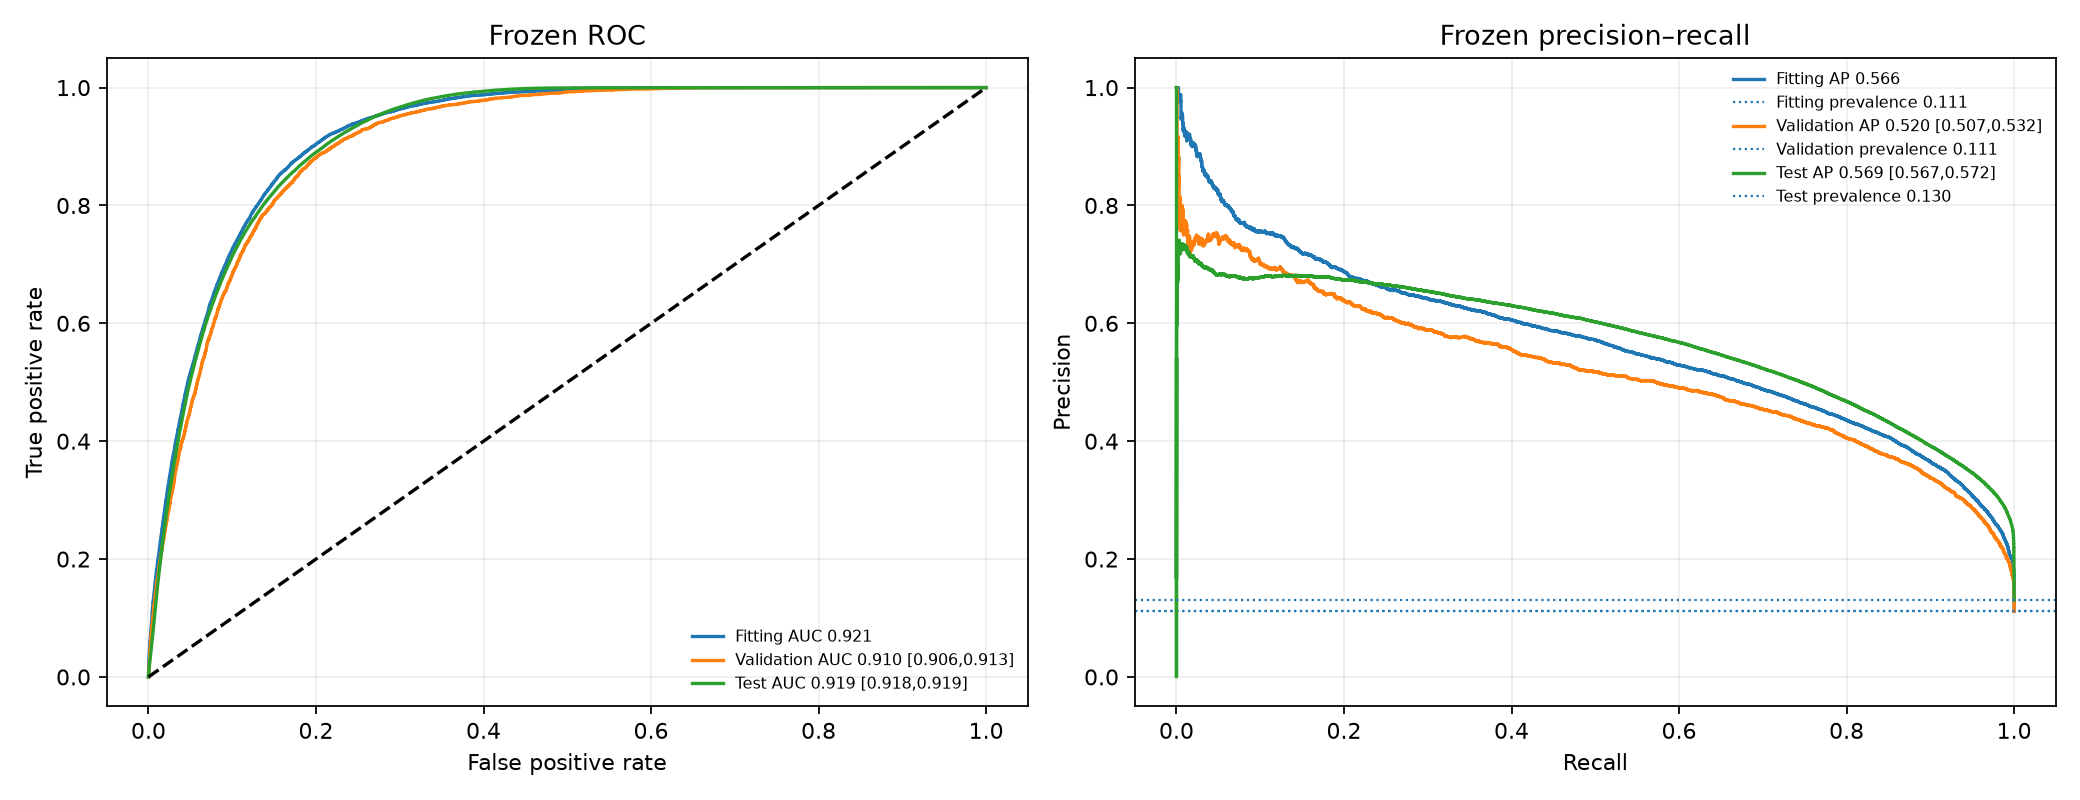

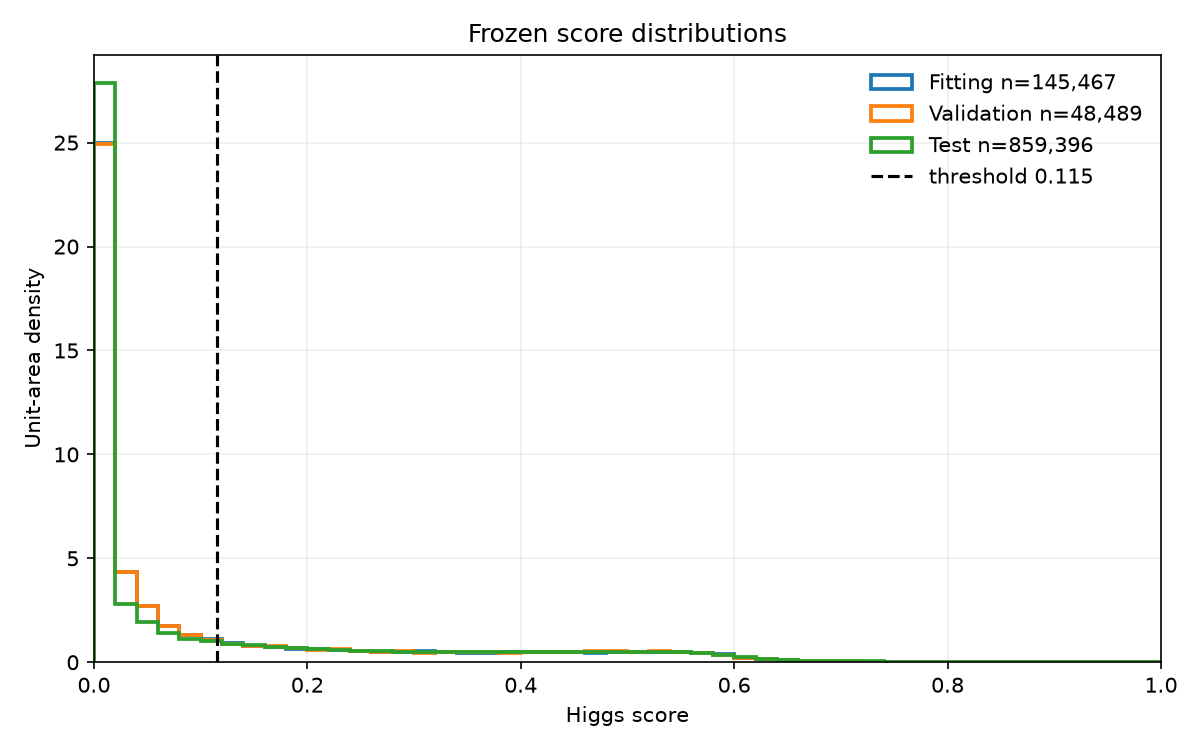

Test confusion matrix [[TN, FP], [FN, TP]]: [[603196 144125]
 [ 13173  98902]]


In [15]:
fig, axs = plt.subplots(1, 2, figsize=(13, 5))
for name, (yy, ss) in splits.items():
    m = frozen_metrics[name]
    fpr, tpr, _ = roc_curve(yy, ss)
    p, r, _ = precision_recall_curve(yy, ss)
    ci = m.get("95pct_CI", {})
    ac = ci.get("ROC-AUC")
    pc = ci.get("average_precision")
    axs[0].plot(
        fpr,
        tpr,
        label=f"{name} AUC {m['ROC-AUC']:.3f}"
        + (f" [{ac[0]:.3f},{ac[1]:.3f}]" if ac else ""),
    )
    axs[1].plot(
        r,
        p,
        label=f"{name} AP {m['average_precision']:.3f}"
        + (f" [{pc[0]:.3f},{pc[1]:.3f}]" if pc else ""),
    )
    axs[1].axhline(
        np.mean(yy), ls=":", lw=1, label=f"{name} prevalence {np.mean(yy):.3f}"
    )
axs[0].plot([0, 1], [0, 1], "k--")
axs[0].set(
    xlabel="False positive rate", ylabel="True positive rate", title="Frozen ROC"
)
axs[1].set(xlabel="Recall", ylabel="Precision", title="Frozen precision–recall")
for ax in axs:
    ax.grid(alpha=0.2)
    ax.legend(frameon=False, fontsize=7)
fig.tight_layout()
fig.savefig(OUT_DIR / "frozen_roc_pr.png", dpi=160)
display(Image(filename=str(OUT_DIR / "frozen_roc_pr.png")))
plt.close(fig)
fig, ax = plt.subplots(figsize=(8, 5))
for name, (yy, ss) in splits.items():
    ax.hist(
        ss,
        bins=np.linspace(0, 1, 51),
        density=True,
        histtype="step",
        lw=1.8,
        label=f"{name} n={len(ss):,}",
    )
ax.axvline(
    FROZEN_THRESHOLD, color="k", ls="--", label=f"threshold {FROZEN_THRESHOLD:.3f}"
)
ax.set(
    xlim=(0, 1),
    xlabel="Higgs score",
    ylabel="Unit-area density",
    title="Frozen score distributions",
)
ax.grid(alpha=0.2)
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(OUT_DIR / "frozen_score_shapes.png", dpi=150)
display(Image(filename=str(OUT_DIR / "frozen_score_shapes.png")))
plt.close(fig)
test_cm = confusion_matrix(y_test[valid], test_score[valid] >= FROZEN_THRESHOLD)
print("Test confusion matrix [[TN, FP], [FN, TP]]:", test_cm)


### Process diagnostics, KS comparisons and feature shift

KS distances and p-values are descriptive. Tied tree scores, large sample sizes, possible overlap and unverified independence limit their interpretation. A non-significant p-value would not prove absence of overtraining.

| label | comparison | n1 | n2 | D | p |
| --- | --- | --- | --- | --- | --- |
| DY | Fitting vs Validation | 29327 | 9776 | 0.0133 | 0.1483 |
| DY | Fitting vs Test | 29327 | 29979 | 0.008047 | 0.2908 |
| DY | Validation vs Test | 9776 | 29979 | 0.006796 | 0.8829 |
| Higgs | Fitting vs Validation | 16188 | 5396 | 0.03342 | 0.0002315 |
| Higgs | Fitting vs Test | 16188 | 112075 | 0.03502 | 1.662e-15 |
| Higgs | Validation vs Test | 5396 | 112075 | 0.01162 | 0.4867 |
| Top | Fitting vs Validation | 15340 | 5113 | 0.01651 | 0.2441 |
| Top | Fitting vs Test | 15340 | 531601 | 0.05393 | 3.974e-38 |
| Top | Validation vs Test | 5113 | 531601 | 0.05057 | 1.081e-11 |
| WW | Fitting vs Validation | 84612 | 28204 | 0.007115 | 0.2335 |
| WW | Fitting vs Test | 84612 | 185741 | 0.005278 | 0.07811 |
| WW | Validation vs Test | 28204 | 185741 | 0.003197 | 0.9631 |

| label | test_count | fraction_above_threshold | Higgs_vs_process_AUC | Higgs_vs_process_AP |
| --- | --- | --- | --- | --- |
| DY | 29979 | 0.1146 | 0.9498 | 0.9855 |
| Higgs | 112075 | 0.8825 | — | — |
| Top | 531601 | 0.1832 | 0.925 | 0.6644 |
| WW | 185741 | 0.233 | 0.8957 | 0.7913 |

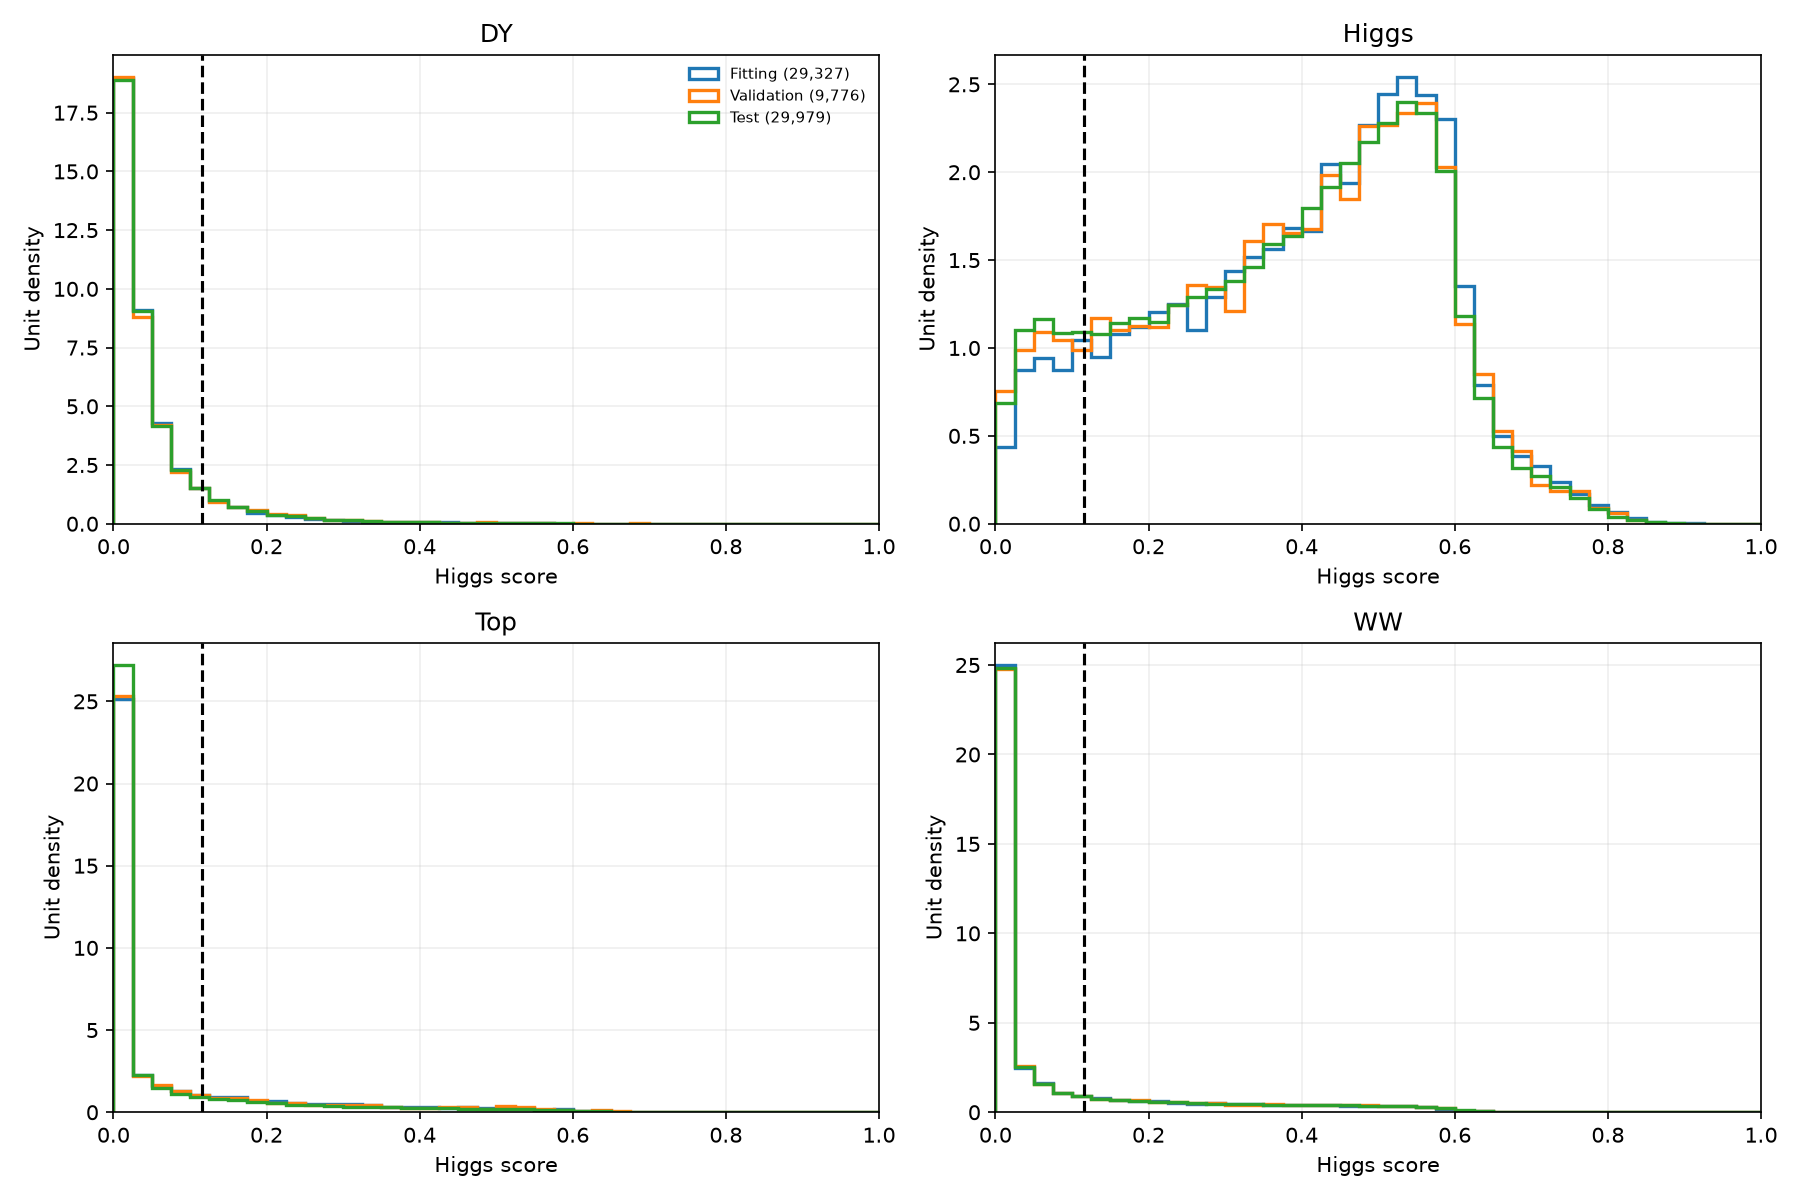

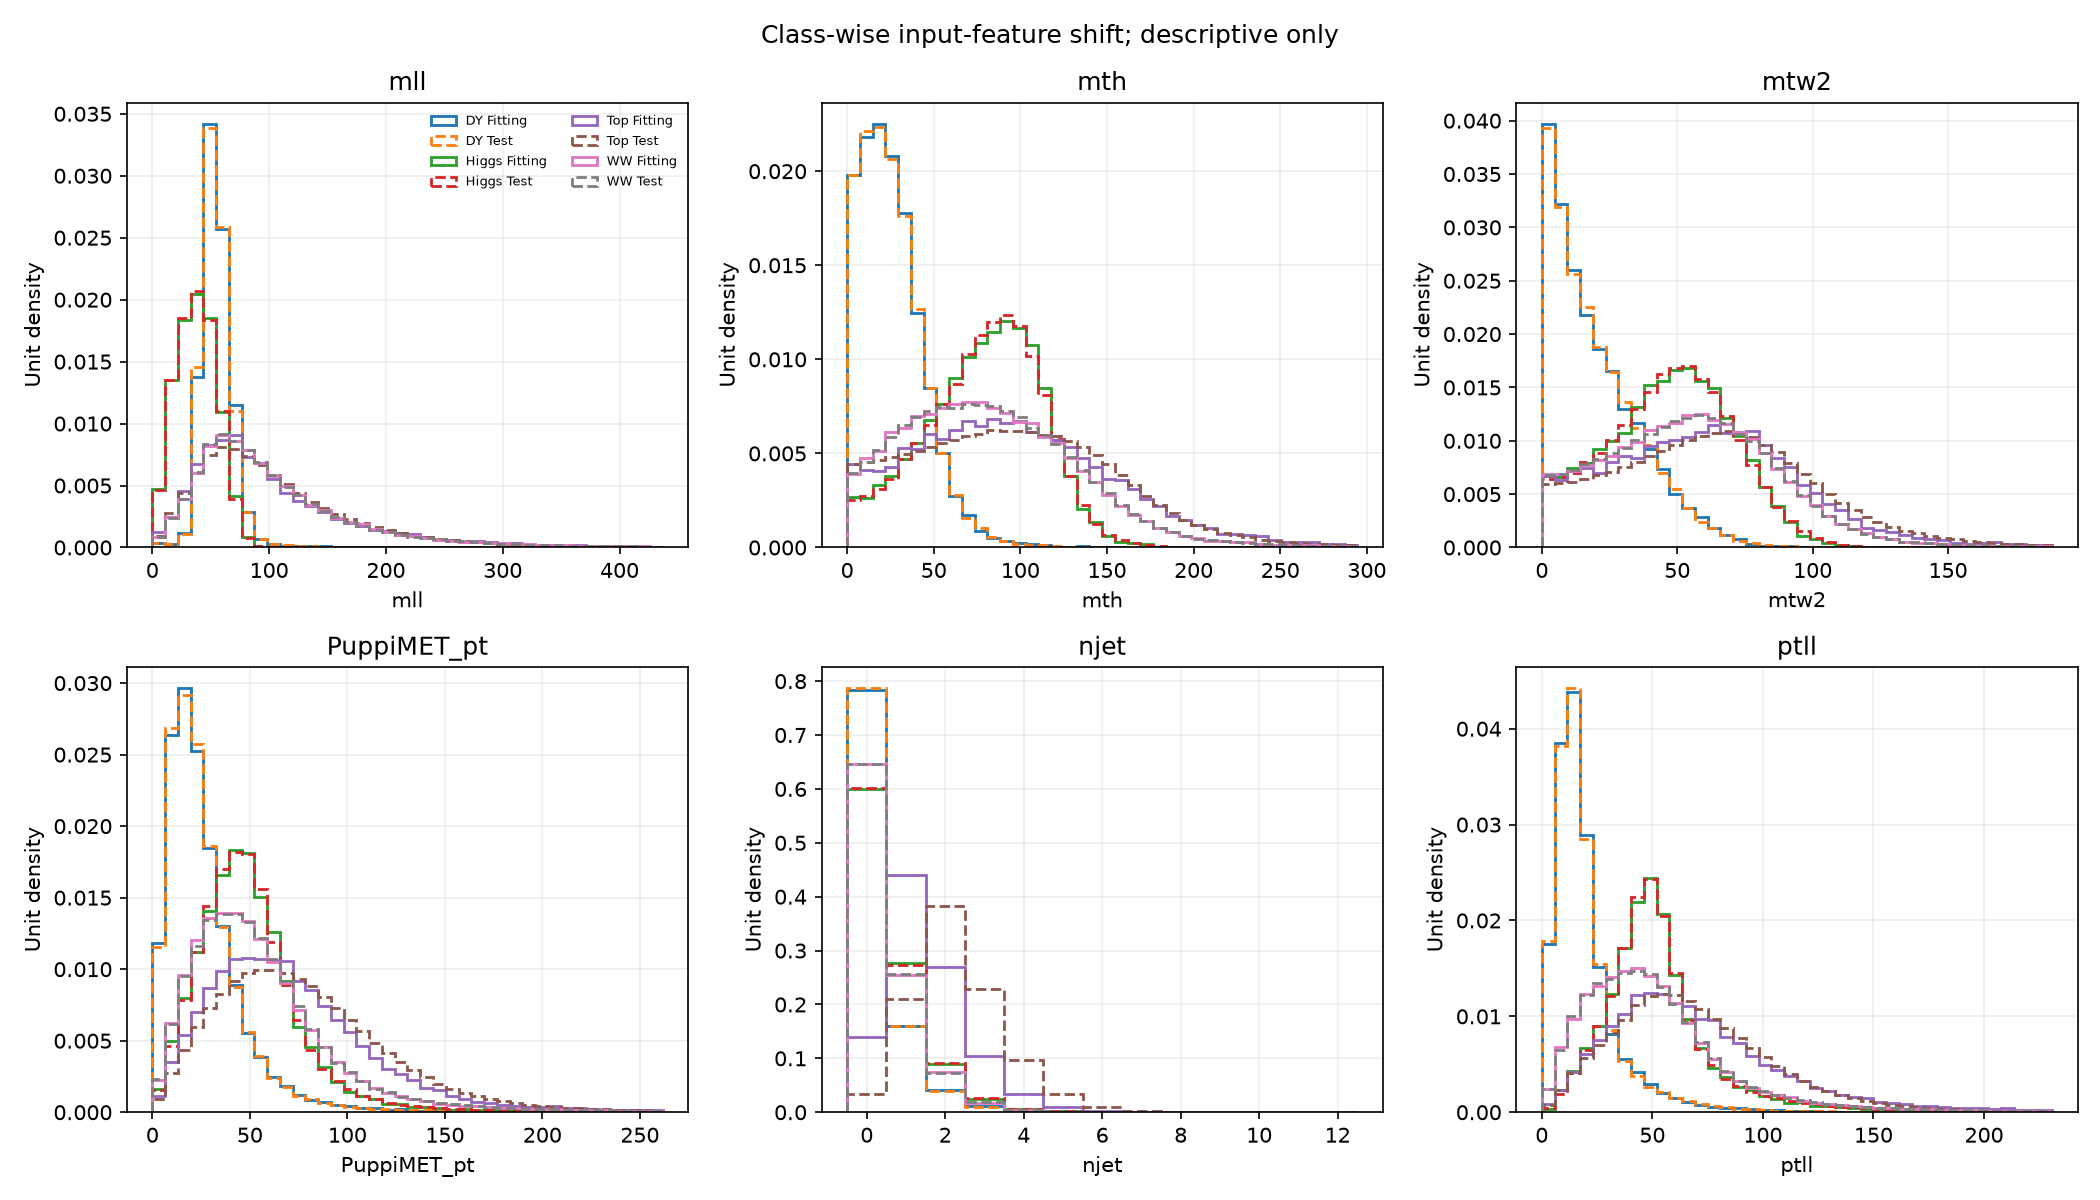

Primary test rows scored: 859,396
Exact feature-vector matches with development rows: 0
Matched-row sensitivity: no matched rows; no secondary exclusion needed
Feature-vector matches do not establish event identity.


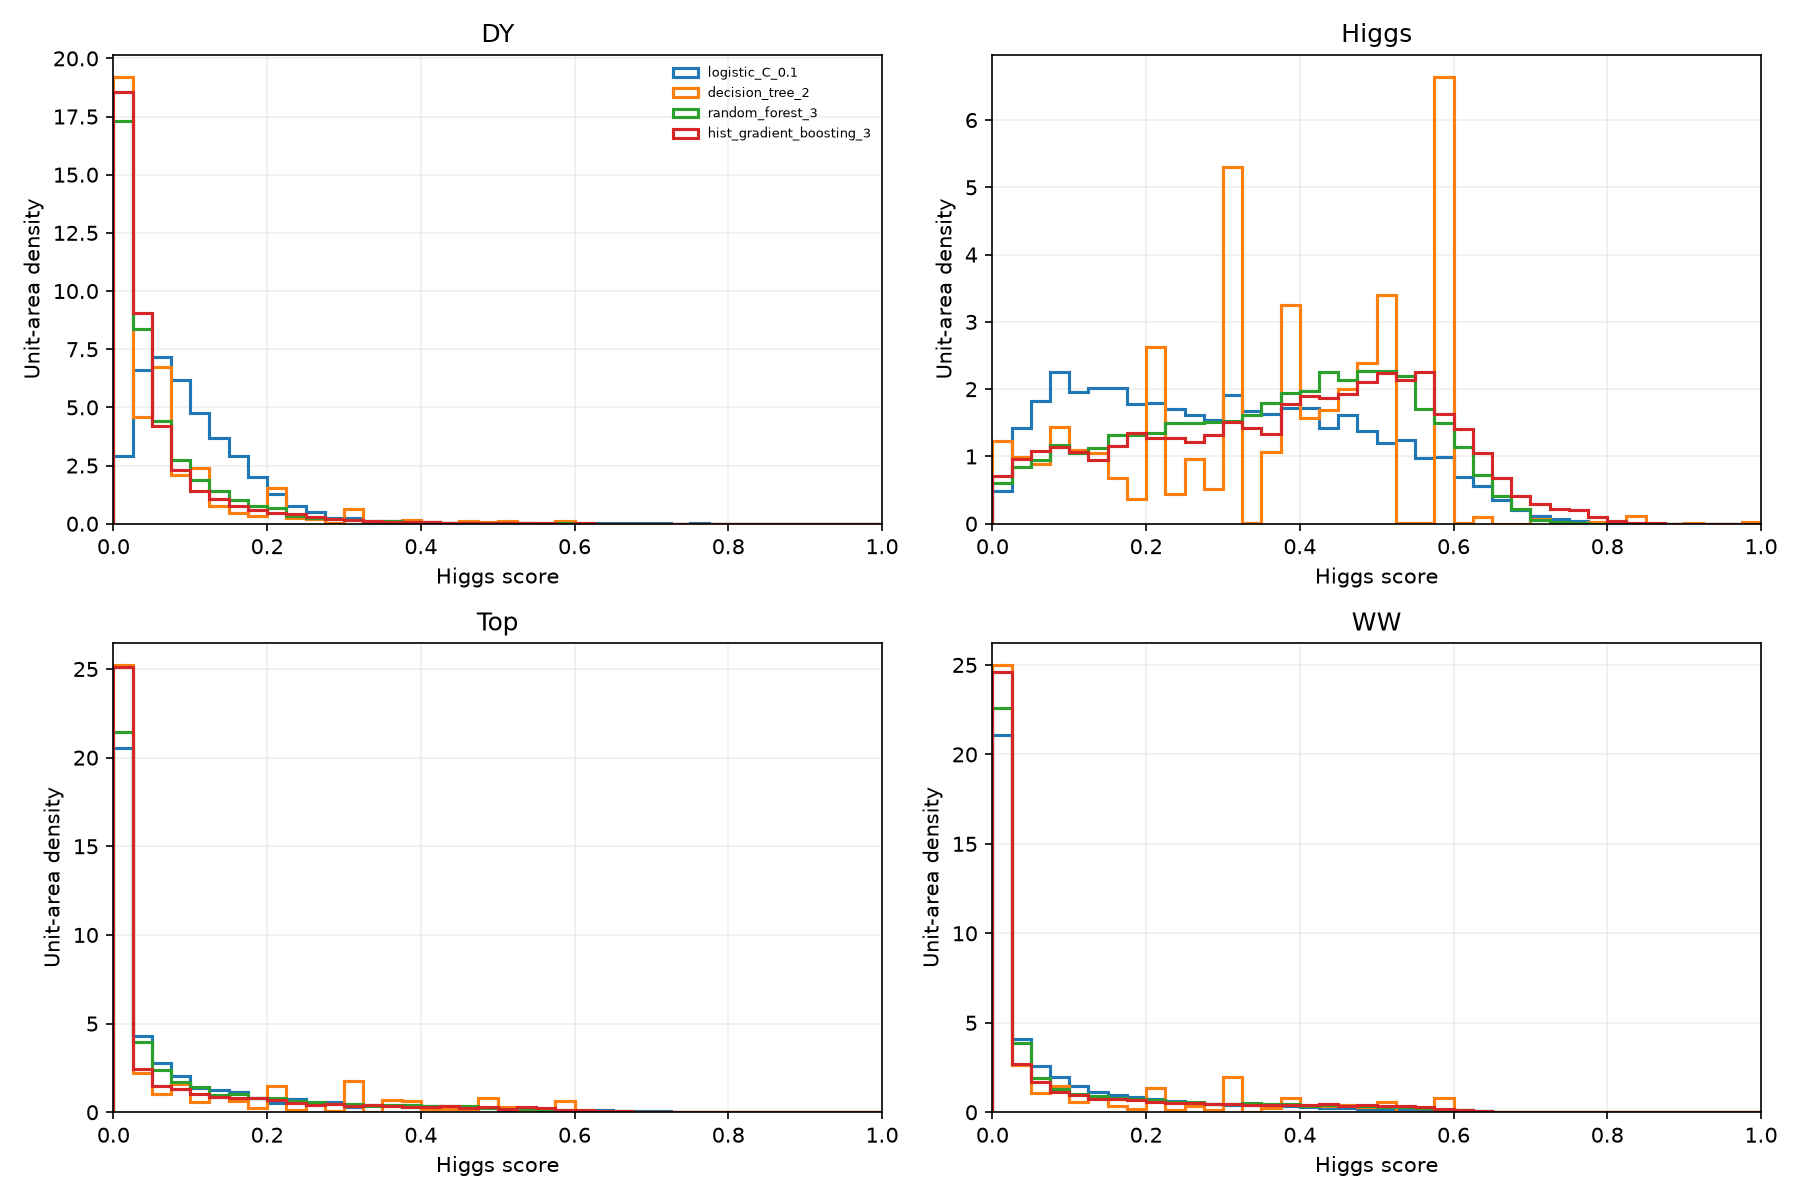

In [16]:
details = {
    "Fitting": (lab_fit, fit_score),
    "Validation": (lab_val, selected_val_score),
    "Test": (lab_test[valid], test_score[valid]),
}
ks_rows = []
for c in CLASSES:
    for s1, s2 in [
        ("Fitting", "Validation"),
        ("Fitting", "Test"),
        ("Validation", "Test"),
    ]:
        l1, a = details[s1]
        l2, b = details[s2]
        u = a[l1 == c]
        v = b[l2 == c]
        k = ks_2samp(u, v, method="auto")
        ks_rows.append(
            {
                "label": c,
                "comparison": s1 + " vs " + s2,
                "n1": len(u),
                "n2": len(v),
                "D": float(k.statistic),
                "p": float(k.pvalue),
            }
        )
display_table(ks_rows)
process_rows = []
for c in CLASSES:
    mask = valid & (lab_test == c)
    sc = test_score[mask]
    row = {
        "label": c,
        "test_count": int(mask.sum()),
        "fraction_above_threshold": float(np.mean(sc >= FROZEN_THRESHOLD)),
    }
    if c != "Higgs":
        pair = valid & np.isin(lab_test, ["Higgs", c])
        row["Higgs_vs_process_AUC"] = float(
            roc_auc_score(y_test[pair], test_score[pair])
        )
        row["Higgs_vs_process_AP"] = float(
            average_precision_score(y_test[pair], test_score[pair])
        )
    process_rows.append(row)
display_table(process_rows)
fig, axs = plt.subplots(2, 2, figsize=(12, 8))
for ax, c in zip(axs.flat, CLASSES):
    for name, (labs, ss) in details.items():
        v = ss[labs == c]
        ax.hist(
            v,
            bins=np.linspace(0, 1, 41),
            density=True,
            histtype="step",
            lw=1.6,
            label=f"{name} ({len(v):,})",
        )
    ax.axvline(FROZEN_THRESHOLD, color="k", ls="--")
    ax.set(xlim=(0, 1), xlabel="Higgs score", ylabel="Unit density", title=c)
    ax.grid(alpha=0.2)
axs[0, 0].legend(frameon=False, fontsize=7)
fig.tight_layout()
fig.savefig(OUT_DIR / "scores_by_process.png", dpi=150)
display(Image(filename=str(OUT_DIR / "scores_by_process.png")))
plt.close(fig)
fig, axs = plt.subplots(2, 3, figsize=(14, 8))
for ax, name in zip(axs.flat, ["mll", "mth", "mtw2", "PuppiMET_pt", "njet", "ptll"]):
    j = FEATURES.index(name)
    allvals = np.r_[X_fit[:, j], X_test[valid, j]]
    hi = np.nanquantile(allvals, 0.995)
    bins = (
        np.arange(np.nanmin(allvals) - 0.5, np.nanmax(allvals) + 1.5, 1)
        if name == "njet"
        else np.linspace(np.nanmin(allvals), hi, 41)
    )
    for c in CLASSES:
        for split, labs, mat, style in [
            ("Fitting", lab_fit, X_fit, "-"),
            ("Test", lab_test[valid], X_test[valid], "--"),
        ]:
            v = mat[labs == c, j]
            ax.hist(
                v,
                bins=bins,
                density=True,
                histtype="step",
                lw=1.35,
                ls=style,
                label=f"{c} {split}",
            )
    ax.set(xlabel=name, ylabel="Unit density", title=name)
    ax.grid(alpha=0.2)
axs[0, 0].legend(frameon=False, fontsize=6, ncol=2)
fig.suptitle("Class-wise input-feature shift; descriptive only")
fig.tight_layout()
fig.savefig(OUT_DIR / "classwise_feature_shift.png", dpi=150)
display(Image(filename=str(OUT_DIR / "classwise_feature_shift.png")))
plt.close(fig)
if overlap.sum():
    keep = valid & ~overlap
    sensitivity = (
        metrics(y_test[keep], test_score[keep], FROZEN_THRESHOLD)
        if len(np.unique(y_test[keep])) == 2
        else "undefined: one class remains"
    )
else:
    keep = valid
    sensitivity = "no matched rows; no secondary exclusion needed"
print(f"Primary test rows scored: {int(valid.sum()):,}")
print(f"Exact feature-vector matches with development rows: {int(overlap.sum()):,}")
if isinstance(sensitivity, dict):
    print("Matched-row sensitivity metrics:")
    display_table([sensitivity])
else:
    print(f"Matched-row sensitivity: {sensitivity}")
print("Feature-vector matches do not establish event identity.")
# Validation score distributions by each filename-derived process for shortlisted models.
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, cls in zip(axes.flat, CLASSES):
    mask = lab_val == cls
    for cid in short_ids:
        ax.hist(
            scores[cid]["validation"][mask],
            bins=np.linspace(0, 1, 41),
            density=True,
            histtype="step",
            lw=1.5,
            label=cid,
        )
    ax.set(xlim=(0, 1), xlabel="Higgs score", ylabel="Unit-area density", title=cls)
    ax.grid(alpha=0.2)
axes[0, 0].legend(frameon=False, fontsize=6)
fig.tight_layout()
fig.savefig(OUT_DIR / "candidate_scores_by_process.png", dpi=150)
display(Image(filename=str(OUT_DIR / "candidate_scores_by_process.png")))
plt.close(fig)


## Conclusion

This measures separation among filename-labelled rows under the stored feature schema. Test files are evaluated in full, but their process identities, upstream selections and event-level independence are unverified. Metrics are unweighted and describe these file compositions, not a physics-normalized CMS sensitivity. KS results are diagnostics rather than proof for or against overtraining; provenance, normalization and sample independence remain necessary for a physics result.

In [17]:
print("Output directory:", OUT_DIR)
print(
    "Eight input inventories:",
    [(r["filename"], r["entries"], r["sha256"]) for r in inventory],
)
print("Search configurations:", len(rows), "feature sets:", len(sets))
print(
    "Selected model:",
    winner["id"],
    "feature set:",
    selected_name,
    "threshold:",
    FROZEN_THRESHOLD,
)
runtime_rows = [
    {"stage": "training ROOT reads", "seconds": training_read_seconds},
    {"stage": "duplicate grouping and split", "seconds": group_split_seconds},
    {"stage": "candidate fits and predictions", "seconds": search_seconds},
    {"stage": "candidate fitting only", "seconds": candidate_fit_seconds},
    {"stage": "candidate paired bootstrap", "seconds": candidate_bootstrap_seconds},
    {"stage": "full-feature permutation importance", "seconds": importance_seconds},
    {"stage": "feature-subset fits and predictions", "seconds": subset_fit_seconds},
    {"stage": "feature-subset paired bootstrap", "seconds": subset_bootstrap_seconds},
    {"stage": "test ROOT reads", "seconds": test_read_seconds},
    {"stage": "test inference", "seconds": test_inference_seconds},
    {"stage": "validation bootstrap", "seconds": bootstrap_seconds["validation"]},
    {"stage": "test bootstrap", "seconds": bootstrap_seconds["test"]},
    {"stage": "active notebook elapsed", "seconds": time.perf_counter() - NOTEBOOK_STARTED},
]
display_table(runtime_rows)
print(
    {
        "available_cpus": CPU_AVAILABLE,
        "hist_gradient_boosting_threads": HGB_THREADS,
        "random_forest_workers": RF_WORKERS,
        "cpu_override": CPU_OVERRIDE,
    }
)


Output directory: /Users/falcon/Documents/docs/hsf-india-bvcoe-2026/outputs/hsf_classification/om_rishabh_hsf_classification_20261016_v6
Eight input inventories: [('DY-train.root', 39103, '65d8e6ef0da05be440e6d38288ef479a9dc9055b9340fabf679a7b54f5367948'), ('Higgs-train.root', 21584, 'efcda212fba7ce344787840f7282a0fb37495861bbc71f1c74ca219c78041195'), ('Top-train.root', 20453, '30beb02050e2c007792bd7313e69fcaba42c564da08db6e3f8b06687f17f4841'), ('WW-train.root', 112816, '3388cb9207ac8fdc3dd3a964522a8047f00b0e5ee58eedfa7c5560d184e494c4'), ('DY-test.root', 29979, '6cc2ef3cf337e3d6a021b1026874b0d4baae1735ca8b8e46aa8866ced9366803'), ('Higgs-test.root', 112075, '68f470682df3a15f59792d0a995ccfc3be34ebe9a5d2dfb6987f064252ca1c13'), ('Top-test.root', 531601, 'ac26218027a3190e8c785a3497f9f9cabe5ed4f2ab47ea20d5ea6769d9b1b3bd'), ('WW-test.root', 185741, 'd1c0a375017360823c756a5994dac2248e2c59ef8a41d150ad70ae959685efe0')]
Search configurations: 12 feature sets: 9
Selected model: hist_gradient_boost

| stage | seconds |
| --- | --- |
| training ROOT reads | 0.2874 |
| duplicate grouping and split | 20.42 |
| candidate fits and predictions | 54.29 |
| candidate fitting only | 53.22 |
| candidate paired bootstrap | 5.649 |
| full-feature permutation importance | 5.019 |
| feature-subset fits and predictions | 13.86 |
| feature-subset paired bootstrap | 14.63 |
| test ROOT reads | 0.779 |
| test inference | 1.669 |
| validation bootstrap | 1.689 |
| test bootstrap | 38.54 |
| active notebook elapsed | 172.7 |

{'available_cpus': 10, 'hist_gradient_boosting_threads': 4, 'random_forest_workers': 8, 'cpu_override': None}
